# Система автоматического извлечения навыков и оценки соответствия резюме вакансиям в IT

## Краткое введение в область задачи
**Dataset**: Resume Dataset — коллекция резюме, собранных с онлайн-источников; используется для задач NLP, классификации резюме и автоматизации рекрутинга.

**Проблема:** рекрутеры просматривают резюме за считанные секунды. Из-за потока кандидатов релевантные люди пропускаются, а ключевые навыки приходится искать вручную.

**Цель:** система, которая автоматически
* извлекает ключевые навыки из текста резюме (NER на основе словаря — spaCy `EntityRuler`);
* оценивает соответствие резюме IT-вакансии (пересечение навыков + TF-IDF cosine);
* формирует рекомендации кандидату.

**Метрики**
| Задача | Метрики |
|---|---|
| Извлечение навыков (NER) | Precision / Recall / F1 — micro по корпусу и macro по документам, на отложенной выборке |
| Ранжирование кандидатов **внутри вакансии** (главная метрика matching) | ρ Спирмена между сходством «резюме — вакансия» и `matched_score` внутри каждой вакансии (среднее по вакансиям + bootstrap 95% CI по вакансиям), Precision@10 (доля верхней десятки среди лучших 20% по `matched_score`) |
| Резюме → вакансии (поиск), вторично | Precision@k, MRR — чувствительны к утечке, см. раздел 10b |
| Итоговый балл продукта ↔ `matched_score` | та же метрика: ρ внутри вакансии |

### Что изменилось по сравнению с предыдущей версией
1. **Три непересекающихся части данных**: `vocab` — из неё строится словарь навыков (EntityRuler); `train` — на ней обучается TF-IDF и классификаторы; `test` — независимая отложенная выборка, из которой **ничего** не строится и не обучается.
2. **Ноутбук запускается с нуля** (Run All): поиск датасета по нескольким путям, `import ast` перенесён наверх (раньше его отсутствие молча ломало построение словаря), функция рекомендаций больше не закомментирована (Groq → если ключа нет, rule-based запасной вариант).
3. Паттерны EntityRuler строятся токенизатором spaCy (раньше `str.split()` — `ci/cd`, `scikit-learn` не могли совпасть).
4. Новые разделы: стемминг vs лемматизация, частотный анализ n-грамм, сравнение BoW / TF-IDF / эмбеддингов / baseline (качество, время, память), матрица ошибок и разбор ошибок.
5. Сохранённые артефакты (`nlp_model/`, `tfidf.pkl`) — это ровно те модели, для которых посчитаны метрики; в конце есть проверка «перезагрузили с диска → метрики совпали».
6. **Разбиение по вакансиям** (`GROUP_COL`): все резюме одной вакансии целиком попадают в одну из частей `vocab` / `train` / `test` (`GroupShuffleSplit`). Раньше резюме одной вакансии были и в `train`, и в `test`, а внутри вакансии резюме устроены «семейством» — метка восстанавливалась тривиально (Accuracy ≈ 100% у всех представлений).
7. **Классификация «резюме → название вакансии» больше не метрика качества**: при разбиении по вакансиям названия из `test` не встречаются в `train`, а при разбиении по строкам задача тривиальна (раздел 10b). Матрица ошибок заменена разбором ранжирования внутри вакансий (раздел 11). Главная метрика — согласие сходства с `matched_score` внутри вакансии.
8. **Входной текст резюме** задаётся `RESUME_FIELDS` (по умолчанию цель + навыки); поле `responsibilities` исключено. Раздел 10b показывает, какие поля выдают вакансию, и содержит абляцию по полям.

> Эталон NER (раздел 5) по-прежнему строится из полей `skills` и `related_skils_in_job` — это отдельная задача, и там эти поля не являются утечкой метки; изменилось только то, что `vocab`/`test` теперь формируются по вакансиям.

## 0. Окружение и конфигурация

In [1]:
import os, sys, re, ast, gc, json, time, pickle, hashlib, platform, importlib, importlib.util, subprocess, tracemalloc, shutil
import warnings
from pathlib import Path
from collections import Counter, defaultdict

def _ensure(pip_name, module=None):
    """Ставит пакет, только если его нет (не трогает уже установленное окружение)."""
    if importlib.util.find_spec(module or pip_name) is None:
        print(f"pip install {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for _pip, _mod in [("numpy", "numpy"), ("pandas", "pandas"), ("scikit-learn", "sklearn"), ("scipy", "scipy"),
                   ("matplotlib", "matplotlib"), ("seaborn", "seaborn"), ("spacy", "spacy"),
                   ("nltk", "nltk"), ("psutil", "psutil")]:
    _ensure(_pip, _mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import spacy
from IPython.display import display

SPACY_MODEL = "en_core_web_md"
if importlib.util.find_spec(SPACY_MODEL) is None:
    from spacy.cli import download
    try:
        download(SPACY_MODEL)
        importlib.invalidate_caches()
    except SystemExit:
        pass
    if importlib.util.find_spec(SPACY_MODEL) is None:
        raise RuntimeError(f"Не удалось установить {SPACY_MODEL}. Выполните вручную: python -m spacy download {SPACY_MODEL}")

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
print("python", platform.python_version(), "| spaCy", spacy.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.12.10 | spaCy 3.8.18 | numpy 2.5.5 | pandas 3.1.1


In [2]:
# ───────────── Конфигурация (всё, что можно менять, — здесь) ─────────────
SEED = 42
rng = np.random.default_rng(SEED)

OUT_DIR = Path(os.environ.get("NLP_OUT_DIR", "."))       # куда сохранить nlp_model/, tfidf.pkl, model_metadata.json
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Доли непересекающихся частей. Делятся ВАКАНСИИ (а не строки), после удаления дубликатов резюме.
SPLIT_FRACTIONS = {"vocab": 0.40, "train": 0.40, "test": 0.20}

# Единица разбиения: все резюме с одним значением этой колонки попадают в одну часть.
#   "job_text" — полный текст вакансии (название + требуемые навыки + обязанности);
#   "label"    — только название вакансии (строже: одно название никогда не окажется в двух частях).
GROUP_COL = "job_text"
assert GROUP_COL in ("job_text", "label"), "GROUP_COL должен быть 'job_text' или 'label'"

# Какие поля резюме формируют входной текст `resume_text` для matching.
# `responsibilities` исключено: вместе с остальными полями оно выдаёт, для какой вакансии написано резюме (см. 10b).
RESUME_FIELDS     = ["career_objective", "skills"]
ALL_RESUME_FIELDS = ["career_objective", "skills", "responsibilities", "related_skils_in_job"]   # для диагностики и абляции (10b)
assert set(RESUME_FIELDS) <= set(ALL_RESUME_FIELDS)

# Название вакансии: описательная статистика и диагностика. НЕ используется как целевая метка классификации.
LABEL_COL = "job_position_name"

# Ранжирование кандидатов внутри вакансии (главная метрика)
MIN_CANDS_PER_VACANCY = 10      # вакансия участвует в ρ / P@10, если в test у неё не меньше стольких резюме с matched_score
TOP_FRAC              = 0.2     # «хорошие» кандидаты = верхние 20% по matched_score внутри вакансии

# Сравнение представлений
SBERT_MODEL   = "sentence-transformers/all-MiniLM-L6-v2"
USE_SBERT     = os.environ.get("USE_SBERT", "auto")      # "auto" — если установлен sentence-transformers и есть доступ к модели; "1" — обязательно; "0" — пропустить
BOOTSTRAP     = 200                                      # число bootstrap-повторов для доверительных интервалов (ресэмплируются вакансии)
NORM_MAX_DOCS = None                                     # ограничить число документов в разделе про лемматизацию (None = все)
print(f"OUT_DIR={OUT_DIR.resolve()}  SEED={SEED}  USE_SBERT={USE_SBERT}  GROUP_COL={GROUP_COL}  RESUME_FIELDS={RESUME_FIELDS}")

OUT_DIR=C:\Users\asd\Documents\GitHub\cv-analyzer-final-project  SEED=42  USE_SBERT=auto  GROUP_COL=job_text  RESUME_FIELDS=['career_objective', 'skills']


## 1. Утилиты препроцессинга
Все вспомогательные функции собраны **до** первого использования (в прежней версии `ast` импортировался позже, чем вызывался `parse_skills_gt`, и ошибка `NameError` молча глоталась `except Exception`).

In [3]:
# Нормализация названий технологий (совпадает с nlp_pipeline.py)
TECH_NORMALIZATIONS = {
    'js': 'javascript', 'py': 'python', 'ml': 'machine learning',
    'dl': 'deep learning', 'nlp': 'natural language processing',
    'tf': 'tensorflow', 'k8s': 'kubernetes', 'db': 'database',
    'oop': 'object oriented programming',
    'react.js': 'react', 'reactjs': 'react',
}
NULL_LIKE = {"none", "nan", "null", "n/a", "na", ""}

def normalize_skill(skill: str) -> str:
    s = skill.lower().strip()
    return TECH_NORMALIZATIONS.get(s, s)

def clean_text(text) -> str:
    if not isinstance(text, str):
        return ""
    text = re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

def _flatten(x):
    if isinstance(x, (list, tuple, set)):
        for i in x:
            yield from _flatten(i)
    elif x is not None:
        yield str(x)

def parse_list_like(raw) -> list:
    """"['Python', 'Docker']" / "[['a','b'], ['c']]" / "a, b" -> плоский список строк."""
    if not isinstance(raw, str):
        return []
    raw = raw.strip()
    if raw.startswith('['):
        try:
            items = ast.literal_eval(raw)
        except Exception:                      # битый список -> режем по запятым
            items = raw.strip('[]').replace("'", '').replace('"', '').split(',')
        out = []
        for s in _flatten(items):
            s = s.strip()
            if s.startswith('['):              # вложенный список, закодированный строкой
                out.extend(parse_list_like(s))
            elif s:
                out.append(s)
        return out
    return [s.strip() for s in raw.split(',') if s.strip()]

def parse_skills_gt(raw) -> set:
    """Строка-список навыков -> множество нормализованных навыков."""
    out = set()
    for item in parse_list_like(raw):
        s = normalize_skill(item)
        if len(s) > 1 and s not in NULL_LIKE:
            out.add(s)
    return out

def to_plain_text(raw) -> str:
    """Список-как-строка превращает в 'a, b, c'; обычный текст возвращает как есть."""
    if not isinstance(raw, str):
        return ""
    s = raw.strip()
    return ", ".join(parse_list_like(s)) if s.startswith('[') else s

def derive_label(raw) -> str:
    if not isinstance(raw, str):
        return ""
    s = raw.strip()
    items = parse_list_like(s) if s.startswith('[') else [s]
    return re.sub(r'\s+', ' ', items[0]).strip().lower() if items else ""

# быстрая самопроверка (ловит тот самый баг с `ast`)
assert parse_skills_gt("['Python', 'Big Data', 'Docker']") == {'python', 'big data', 'docker'}
assert parse_skills_gt("[['Python','SQL'], ['Docker']]") == {'python', 'sql', 'docker'}
print("Функции препроцессинга готовы")

Функции препроцессинга готовы


## 2. Загрузка данных
Путь к датасету ищется в нескольких местах (переменная окружения `RESUME_CSV`, рядом с ноутбуком, `/kaggle/input/**`), в конце — `kagglehub`. Прежний жёстко зашитый путь `/kaggle/input/datasets/...` в Kaggle не существует.

In [4]:
def find_dataset(filename="resume_data.csv") -> Path:
    candidates = []
    if os.environ.get("RESUME_CSV"):
        candidates.append(Path(os.environ["RESUME_CSV"]))
    candidates += [Path(filename), Path("data") / filename, Path("..") / "data" / filename, Path("..") / filename]
    for p in candidates:
        if p.is_file():
            return p
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for p in kaggle_input.rglob(filename):
            return p
    try:                                                    # локальный запуск с настроенным Kaggle API
        import kagglehub
        d = Path(kagglehub.dataset_download("saugataroyarghya/resume-dataset"))
        for p in d.rglob(filename):
            return p
    except Exception as exc:
        print("kagglehub недоступен:", repr(exc)[:120])
    raise FileNotFoundError(
        f"Не найден {filename}. Скачайте датасет https://www.kaggle.com/datasets/saugataroyarghya/resume-dataset "
        "и положите рядом с ноутбуком или задайте переменную окружения RESUME_CSV=/путь/к/resume_data.csv")

DATA_PATH = find_dataset()
try:
    df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig", low_memory=False)
except UnicodeDecodeError:
    df_raw = pd.read_csv(DATA_PATH, encoding="latin-1", low_memory=False)
df_raw.columns = [c.replace("\ufeff", "").strip() for c in df_raw.columns]    # в датасете BOM внутри имени колонки job_position_name

REQUIRED = ["career_objective", "skills", "related_skils_in_job", "responsibilities", LABEL_COL,
            "job_position_name", "skills_required", "responsibilities.1", "matched_score"]
missing = [c for c in dict.fromkeys(REQUIRED) if c not in df_raw.columns]
if missing:
    raise KeyError(f"В датасете нет колонок: {missing}. Есть: {df_raw.columns.tolist()}")

DATA_MD5 = hashlib.md5(DATA_PATH.read_bytes()).hexdigest()
print("Файл:", DATA_PATH, "| md5:", DATA_MD5)
print("Размер датасета:", df_raw.shape)
print("\nПропущенные значения (топ-10):")
print(df_raw.isnull().sum().sort_values(ascending=False).head(10))

Файл: data\resume_data.csv | md5: 95e9272dfbdabb0b8f96403b9bf5852e
Размер датасета: (9544, 35)

Пропущенные значения (топ-10):
languages                              8844
proficiency_levels                     8844
address                                8760
issue_dates                            7536
certification_skills                   7536
certification_providers                7536
expiry_dates                           7536
online_links                           7536
extra_curricular_activity_types        6118
extra_curricular_organization_links    6118
dtype: int64


## 3. EDA: разведочный анализ данных

Статистика matched_score:
count    9544.00
mean        0.66
std         0.17
min         0.00
25%         0.58
50%         0.68
75%         0.79
max         0.97
Name: matched_score, dtype: float64


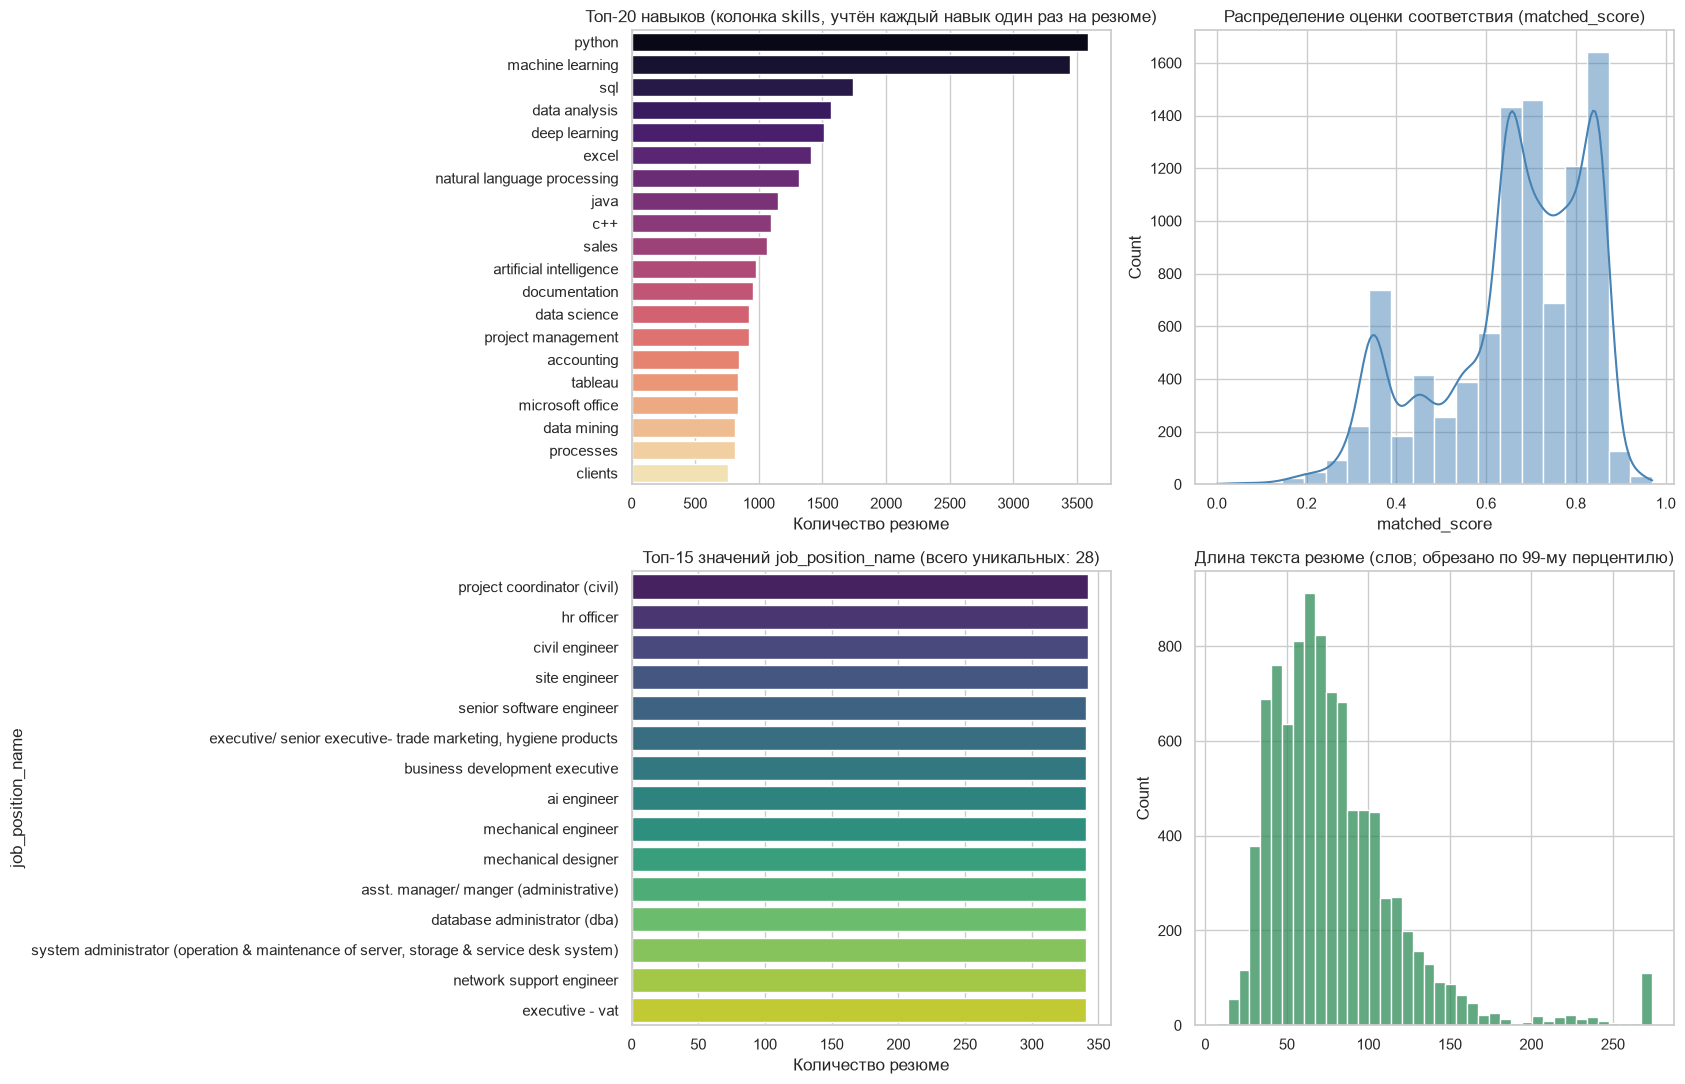

In [5]:
all_skill_sets = df_raw["skills"].dropna().map(parse_skills_gt)
top_skills = Counter(s for sk in all_skill_sets for s in sk).most_common(20)
labels_raw = df_raw[LABEL_COL].map(derive_label)
top_titles = labels_raw[labels_raw != ""].value_counts().head(15)
n_words_raw = (df_raw["career_objective"].map(to_plain_text) + " " + df_raw["skills"].map(to_plain_text)
               + " " + df_raw["responsibilities"].map(to_plain_text)).str.split().str.len()

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
sns.barplot(x=[x[1] for x in top_skills], y=[x[0] for x in top_skills], hue=[x[0] for x in top_skills],
            palette='magma', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Топ-20 навыков (колонка skills, учтён каждый навык один раз на резюме)')
axes[0, 0].set_xlabel('Количество резюме')

scores = pd.to_numeric(df_raw['matched_score'], errors='coerce').dropna()
sns.histplot(scores, bins=20, kde=True, color='steelblue', ax=axes[0, 1])
axes[0, 1].set_title('Распределение оценки соответствия (matched_score)')
print(f"Статистика matched_score:\n{scores.describe().round(2)}")

sns.barplot(x=top_titles.values, y=top_titles.index, hue=top_titles.index, palette='viridis', legend=False, ax=axes[1, 0])
axes[1, 0].set_title(f'Топ-15 значений {LABEL_COL} (всего уникальных: {labels_raw.nunique()})')
axes[1, 0].set_xlabel('Количество резюме')

sns.histplot(n_words_raw.dropna().clip(upper=n_words_raw.quantile(0.99)), bins=40, color='seagreen', ax=axes[1, 1])
axes[1, 1].set_title('Длина текста резюме (слов; обрезано по 99-му перцентилю)')
plt.tight_layout(); plt.show()

## 4. Подготовка текстов и разбиение на `vocab` / `train` / `test` — по вакансиям
* `resume_text` = поля `RESUME_FIELDS` (по умолчанию цель + навыки); списки в виде строк `"['a', 'b']"` превращаются в обычный текст, чтобы скобки и кавычки не попадали в TF-IDF. `resume_text_full` (все четыре поля) нужен только для поиска дубликатов и для диагностики/абляции в разделе 10b;
* `job_text` = название + требуемые навыки + обязанности вакансии;
* точные дубликаты резюме удаляются **до** разбиения;
* **разбиваются вакансии, а не строки** (`GroupShuffleSplit` по `GROUP_COL`): все резюме одной вакансии оказываются в одной части. Раньше разбиение шло по строкам, и «семейства» резюме одной вакансии попадали и в `train`, и в `test` — отсюда ≈100% Accuracy (раздел 10b).

In [6]:
from sklearn.model_selection import GroupShuffleSplit

def build_resume_text(rows, fields):
    """Склеивает выбранные поля резюме в один текст (списки-как-строки превращаются в обычный текст)."""
    out = rows[fields[0]].map(to_plain_text)
    for f in fields[1:]:
        out = out + " " + rows[f].map(to_plain_text)
    return out.map(clean_text)

df = df_raw.copy()
df["resume_text"]      = build_resume_text(df, RESUME_FIELDS)          # вход для matching
df["resume_text_full"] = build_resume_text(df, ALL_RESUME_FIELDS)      # только для дубликатов и диагностики (10b)
df["job_text"] = (df["job_position_name"].map(to_plain_text) + " " + df["skills_required"].map(to_plain_text)
                  + " " + df["responsibilities.1"].map(to_plain_text)).map(clean_text)
df["label"] = df[LABEL_COL].map(derive_label)                          # название вакансии (описательно; не целевая метка)
df["matched_score"] = pd.to_numeric(df["matched_score"], errors="coerce")
df["n_words"] = df["resume_text"].str.split().str.len()

n0 = len(df)
df = df[df["n_words"] >= 3]
n1 = len(df)
df = df.drop_duplicates(subset="resume_text_full").reset_index(drop=True)
print(f"Строк: {n0} → без пустых: {n1} → без дубликатов резюме: {len(df)}")

# идентификатор вакансии = группа разбиения (пустой ключ не склеивает неизвестные вакансии в одну группу)
_gkey = df[GROUP_COL].where(df[GROUP_COL] != "", "__empty__" + df.index.astype(str))
df["vacancy_id"] = pd.factorize(_gkey)[0]

def split3_groups(groups, fr, seed):
    """Делит ВАКАНСИИ (группы), а не строки: все резюме одной вакансии остаются в одной части."""
    assert abs(sum(fr.values()) - 1) < 1e-9
    groups = np.asarray(groups)
    if len(np.unique(groups)) < 10:
        raise ValueError(f"Слишком мало разных вакансий ({len(np.unique(groups))}) для разбиения по вакансиям; проверьте GROUP_COL.")
    idx = np.arange(len(groups))
    i_vocab, i_rest = next(GroupShuffleSplit(n_splits=1, train_size=fr["vocab"], random_state=seed).split(idx, groups=groups))
    j_train, j_test = next(GroupShuffleSplit(n_splits=1, train_size=fr["train"] / (fr["train"] + fr["test"]),
                                             random_state=seed).split(i_rest, groups=groups[i_rest]))
    return i_vocab, i_rest[j_train], i_rest[j_test]

i_vocab, i_train, i_test = split3_groups(df["vacancy_id"].to_numpy(), SPLIT_FRACTIONS, SEED)
df["split"] = ""
df.loc[i_vocab, "split"] = "vocab"
df.loc[i_train, "split"] = "train"
df.loc[i_test,  "split"] = "test"

# контроль: части не пересекаются ни по строкам, ни по вакансиям
assert (df["split"] != "").all() and len(set(i_vocab) & set(i_train)) == len(set(i_vocab) & set(i_test)) == len(set(i_train) & set(i_test)) == 0
_vac = {s: set(df.loc[df["split"] == s, "vacancy_id"]) for s in ("vocab", "train", "test")}
assert not (_vac["vocab"] & _vac["train"]) and not (_vac["vocab"] & _vac["test"]) and not (_vac["train"] & _vac["test"]), "одна вакансия попала в две части — утечка"
assert df["resume_text_full"].is_unique, "дубликаты текстов между частями — утечка"

_sizes = df.groupby(["split", "vacancy_id"]).size()
summary = df.groupby("split").agg(резюме=("resume_text", "size"), вакансий=("vacancy_id", "nunique"),
                                  с_оценкой_matched_score=("matched_score", lambda s: int(s.notna().sum())))
summary["вакансий с ≥ MIN_CANDS резюме"] = _sizes.groupby(level="split").apply(lambda s: int((s >= MIN_CANDS_PER_VACANCY).sum()))
display(summary.loc[["vocab", "train", "test"]])

_titles = {s: set(df.loc[df["split"] == s, "label"]) - {""} for s in ("vocab", "train", "test")}
print(f"Контроль: общих вакансий между частями — 0. Общих НАЗВАНИЙ train∩test: {len(_titles['train'] & _titles['test'])} из {len(_titles['test'])} в test"
      + ("" if GROUP_COL == "label" else "  (при GROUP_COL='job_text' одинаковое название у разных текстов вакансии допустимо; для строгого режима поставьте GROUP_COL='label')"))
_n_ms = int(df.loc[df["split"] == "test", "matched_score"].notna().sum())
print(f"Резюме в test: {int((df['split'] == 'test').sum())}, из них с matched_score: {_n_ms}")

Строк: 9544 → без пустых: 9488 → без дубликатов резюме: 9488


,резюме,вакансий,с_оценкой_matched_score,вакансий с ≥ MIN_CANDS резюме
split,,,,
vocab,3727,11,3727,11
train,3728,11,3728,11
test,2033,6,2033,6


Контроль: общих вакансий между частями — 0. Общих НАЗВАНИЙ train∩test: 0 из 6 в test  (при GROUP_COL='job_text' одинаковое название у разных текстов вакансии допустимо; для строгого режима поставьте GROUP_COL='label')
Резюме в test: 2033, из них с matched_score: 2033


## 5. Извлечение навыков (NER) — словарь строится только из части `vocab`
**Что было не так.** Словарь `EntityRuler` строился из колонок `skills` и `related_skils_in_job` **всех** резюме, а затем качество считалось на первых 200 строках **того же** датасета, подавая на вход ту же колонку `skills`. Это измеряет, насколько словарь знает собственный источник (утечка), а не способность находить навыки в новых резюме. Кроме того, `related_skils_in_job` входило в эталон, но не во вход — это искусственно занижало recall.

**Как теперь.**
* Словарь = навыки из части `vocab` + кураторский список `EXTRA_SKILLS` (он же `SKILLS_VOCAB` из `nlp_pipeline.py`).
* Оценка — на части `test` (резюме, которых нет ни в словаре, ни в обучении TF-IDF). Вход: тексты полей `skills` и `related_skils_in_job`; эталон: объединение их разобранных значений — то есть эталон полностью выводим из входа.
* Для наглядности сравниваются варианты: старый протокол, «утёкший» словарь, честный словарь, честный словарь без кураторского списка, только кураторский список.
* Паттерны строятся токенизатором spaCy (`nlp.make_doc`), а не `str.split()`.
* Для нормализованных навыков добавляются паттерны-алиасы (`react` → `react.js`, `machine learning` → `ml`): раньше `react.js` нормализовался в `react` ещё до построения словаря, и написание «React.js» в тексте не находилось.

In [7]:
EXTRA_SKILLS = [
    # Languages
    "python", "javascript", "typescript", "java", "c++", "c#", "golang", "rust",
    "kotlin", "swift", "scala", "r", "php", "ruby", "bash", "sql", "html", "css",
    "sass", "core java",
    # ML / AI
    "machine learning", "deep learning", "natural language processing",
    "computer vision", "data science", "data analysis", "data engineering",
    "scikit-learn", "tensorflow", "pytorch", "keras", "hugging face",
    "transformers", "bert", "gpt", "langchain", "openai", "llm",
    "reinforcement learning", "feature engineering", "model deployment",
    "mlflow", "xgboost", "lightgbm", "catboost", "random forest",
    "neural network", "convolutional neural network", "recurrent neural network",
    "risk prediction", "big data",
    # Data
    "data visualization", "data analytics", "business analytics", "business analysis",
    "data warehousing", "business intelligence", "tableau", "power bi",
    "apache spark", "spark", "pyspark", "hadoop", "hive", "kafka", "airflow",
    "dbt", "etl", "pandas", "numpy", "matplotlib", "seaborn",
    "amazon redshift", "google bigquery", "azure synapse", "snowflake",
    # Cloud & DevOps
    "aws", "azure", "gcp", "docker", "kubernetes", "terraform", "ansible",
    "ci/cd", "github actions", "jenkins", "linux", "nginx", "redis",
    "cloud computing", "microservices", "serverless",
    # Databases
    "postgresql", "mongodb", "mysql", "sqlite", "elasticsearch", "cassandra",
    "dynamodb", "firebase", "nosql",
    # Backend
    "fastapi", "flask", "django", "spring boot", "node.js", "express.js",
    "rest api", "graphql", "grpc", "websocket", "celery",
    # Frontend
    "react", "react.js", "vue.js", "angular", "next.js", "nuxt.js",
    "tailwind", "webpack", "vite", "redux", "typescript",
    # Tools
    "git", "github", "gitlab", "jira", "confluence", "figma",
    "agile", "scrum", "kanban",
    # Other
    "application support", "network security", "system administration",
    "unity", "unreal engine", "opencv", "selenium", "pytest",
]
CURATED = {normalize_skill(s) for s in EXTRA_SKILLS}

ALIASES = defaultdict(set)                                    # нормализованный навык -> написания, которые к нему приводятся
for _alias, _canon in TECH_NORMALIZATIONS.items():
    ALIASES[_canon].add(_alias)

def skills_from_rows(rows) -> set:
    out = set()
    for col in ("skills", "related_skils_in_job"):
        for raw in rows[col].dropna():
            out |= parse_skills_gt(raw)
    return out

def build_ner(skills, base="blank"):
    """EntityRuler со словарём skills. base='blank' — быстрый вариант для оценки (токенизатор идентичен en_core_web_md),
    base='md' — продуктовая модель (как раньше: en_core_web_md без NER + EntityRuler)."""
    nlp_ = spacy.blank("en") if base == "blank" else spacy.load(SPACY_MODEL, disable=["ner"])
    ruler = nlp_.add_pipe("entity_ruler", config={"overwrite_ents": True})
    # Навыки хранятся в нормализованном виде ('react'), а в тексте встречаются написания-алиасы ('react.js', 'NLP', 'K8s').
    # Паттерны строим и для нормализованной формы, и для её алиасов (из TECH_NORMALIZATIONS); на выходе всё снова нормализуется.
    forms = set()
    for sk in skills:
        forms.add(sk.strip())
        forms.update(ALIASES.get(sk.strip(), ()))
    seen, patterns = set(), []
    for sk in sorted(forms):
        if len(sk) < 2:
            continue
        toks = tuple(t.lower_ for t in nlp_.make_doc(sk))
        if toks and toks not in seen:
            seen.add(toks)
            patterns.append({"label": "SKILL", "pattern": [{"LOWER": t} for t in toks]})
    ruler.add_patterns(patterns)
    return nlp_, len(patterns)

def predict_skills(nlp_, texts, batch_size=128):
    return [{normalize_skill(e.text) for e in doc.ents if e.label_ == "SKILL"}
            for doc in nlp_.pipe([clean_text(t) for t in texts], batch_size=batch_size)]

def eval_ner(preds, golds):
    TP = FP = FN = 0
    P, R, F = [], [], []
    fn_c, fp_c = Counter(), Counter()
    for p, g in zip(preds, golds):
        if not p and not g:
            continue
        tp, fp, fn = p & g, p - g, g - p
        TP += len(tp); FP += len(fp); FN += len(fn)
        fn_c.update(fn); fp_c.update(fp)
        pr = len(tp) / len(p) if p else 0.0
        rc = len(tp) / len(g) if g else 0.0
        P.append(pr); R.append(rc); F.append(2 * pr * rc / (pr + rc) if pr + rc else 0.0)
    p_ = TP / (TP + FP) if TP + FP else 0.0
    r_ = TP / (TP + FN) if TP + FN else 0.0
    return dict(n_docs=len(F), TP=TP, FP=FP, FN=FN,
                P_micro=p_, R_micro=r_, F1_micro=2 * p_ * r_ / (p_ + r_) if p_ + r_ else 0.0,
                P_macro=float(np.mean(P)), R_macro=float(np.mean(R)), F1_macro=float(np.mean(F)),
                fn_counter=fn_c, fp_counter=fp_c)

def ner_gold(rows):
    return [parse_skills_gt(a) | parse_skills_gt(b) for a, b in zip(rows["skills"], rows["related_skils_in_job"])]

def ner_input(rows, mode="fixed"):
    if mode == "skills_only":
        return [to_plain_text(a) for a in rows["skills"]]
    return [to_plain_text(a) + ", " + to_plain_text(b) for a, b in zip(rows["skills"], rows["related_skils_in_job"])]

vocab_rows = df[df["split"] == "vocab"]
test_rows  = df[df["split"] == "test"]
VOCAB_SKILLS = skills_from_rows(vocab_rows)           # только из части vocab
ALL_SKILLS   = skills_from_rows(df)                   # для демонстрации утечки
print(f"Навыков в части vocab: {len(VOCAB_SKILLS)} | во всём датасете: {len(ALL_SKILLS)} | кураторский список: {len(CURATED)}")
print(f"Навыков из теста, которых нет в vocab-части: {len(skills_from_rows(test_rows) - VOCAB_SKILLS)} из {len(skills_from_rows(test_rows))}")

Навыков в части vocab: 3911 | во всём датасете: 3911 | кураторский список: 138
Навыков из теста, которых нет в vocab-части: 0 из 3911


In [8]:
gold_test = ner_gold(test_rows)
variants = {}

# (0) старый протокол: словарь из ВСЕХ строк, первые 200 строк, вход = только skills, эталон = skills ∪ related
old_rows = df.dropna(subset=["skills"]).head(200)
nlp_old, n_old = build_ner(ALL_SKILLS | CURATED)
variants["0. Старый протокол (словарь из всех строк, 200 строк, вход=skills)"] = (
    eval_ner(predict_skills(nlp_old, ner_input(old_rows, "skills_only")), ner_gold(old_rows)), n_old)

# (1) утечка: словарь из всех строк (включая test), новый протокол, тест
variants["1. Утечка: словарь из ВСЕХ строк, оценка на test"] = (
    eval_ner(predict_skills(nlp_old, ner_input(test_rows)), gold_test), n_old)

# (2) ЧЕСТНО: vocab-часть + кураторский список   ← используется дальше и сохраняется
nlp_eval, n_eval = build_ner(VOCAB_SKILLS | CURATED)
preds_test = predict_skills(nlp_eval, ner_input(test_rows))
res_main = eval_ner(preds_test, gold_test)
variants["2. ЧЕСТНО: vocab-часть + кураторский список (используется в продукте)"] = (res_main, n_eval)

# (3) честно, без кураторского списка
nlp_nocur, n_nocur = build_ner(VOCAB_SKILLS)
variants["3. Честно, только vocab-часть (без кураторского списка)"] = (eval_ner(predict_skills(nlp_nocur, ner_input(test_rows)), gold_test), n_nocur)

# (4) только кураторский список (словарь «из головы»)
nlp_cur, n_cur = build_ner(CURATED)
variants["4. Только кураторский список (без данных)"] = (eval_ner(predict_skills(nlp_cur, ner_input(test_rows)), gold_test), n_cur)

ner_table = pd.DataFrame(
    [{"вариант": k, "паттернов": n, "docs": r["n_docs"], "P (micro)": r["P_micro"], "R (micro)": r["R_micro"],
      "F1 (micro)": r["F1_micro"], "P (macro)": r["P_macro"], "R (macro)": r["R_macro"], "F1 (macro)": r["F1_macro"]}
     for k, (r, n) in variants.items()]).set_index("вариант")
display(ner_table.round(3))

leak_gap = variants["1. Утечка: словарь из ВСЕХ строк, оценка на test"][0]["F1_micro"] - res_main["F1_micro"]
print(f"\nЗавышение F1(micro) из-за утечки словаря: {leak_gap:+.3f} (утечка {variants['1. Утечка: словарь из ВСЕХ строк, оценка на test'][0]['F1_micro']:.3f} → честно {res_main['F1_micro']:.3f})")

,паттернов,docs,P (micro),R (micro),F1 (micro),P (macro),R (macro),F1 (macro)
вариант,,,,,,,,
"0. Старый протокол (словарь из всех строк, 200 строк, вход=skills)",3970,199,0.999,0.781,0.877,0.999,0.805,0.877
"1. Утечка: словарь из ВСЕХ строк, оценка на test",3970,2021,1.000,0.999,1.000,1.000,1.000,1.000
2. ЧЕСТНО: vocab-часть + кураторский список (используется в продукте),3970,2021,1.000,0.999,1.000,1.000,1.000,1.000
"3. Честно, только vocab-часть (без кураторского списка)",3922,2021,1.000,0.999,1.000,1.000,1.000,1.000
4. Только кураторский список (без данных),146,2021,0.920,0.132,0.231,0.575,0.250,0.323



Завышение F1(micro) из-за утечки словаря: +0.000 (утечка 1.000 → честно 1.000)


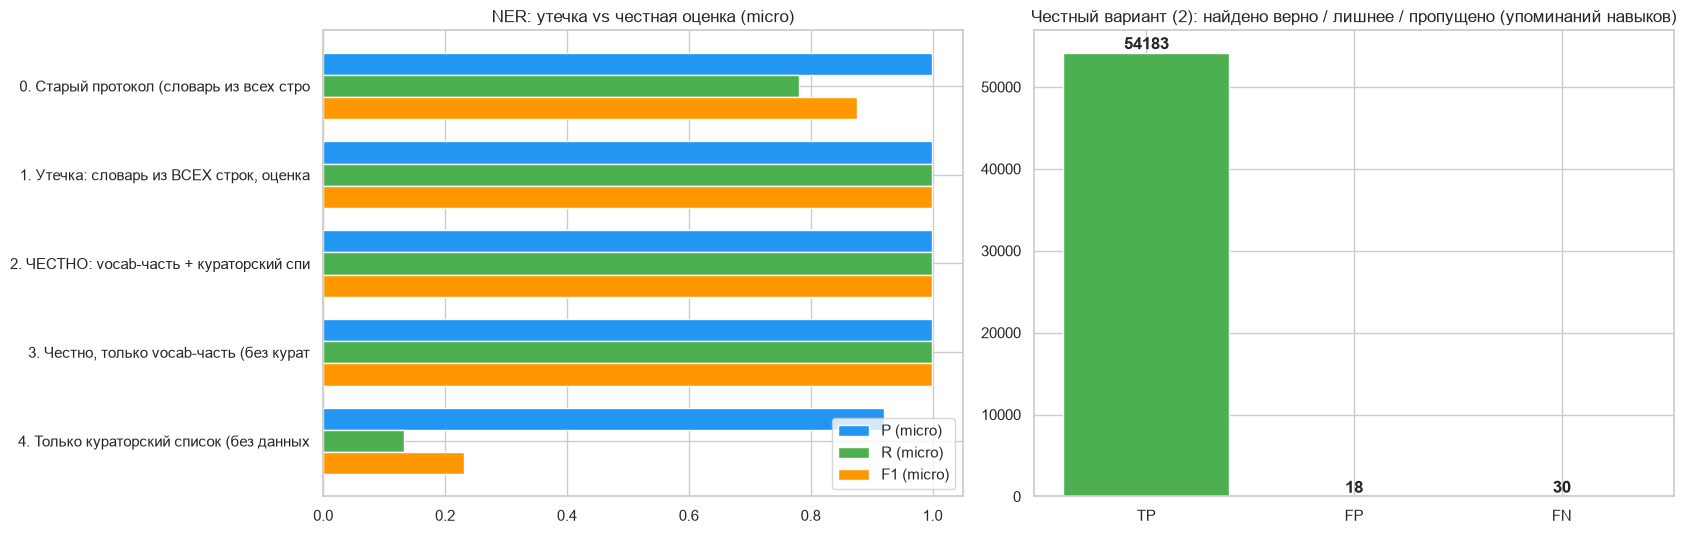

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
plot_df = ner_table[["P (micro)", "R (micro)", "F1 (micro)"]].copy()
plot_df.index = [i.split(".")[0] + "." + i.split(".")[1][:38] for i in plot_df.index]
plot_df.plot(kind="barh", ax=axes[0], color=['#2196F3', '#4CAF50', '#FF9800'], width=0.75)
axes[0].set_xlim(0, 1.05); axes[0].invert_yaxis(); axes[0].set_title("NER: утечка vs честная оценка (micro)")
axes[0].legend(loc="lower right")
axes[1].bar(["TP", "FP", "FN"], [res_main["TP"], res_main["FP"], res_main["FN"]], color=["#4CAF50", "#F44336", "#9E9E9E"])
for i, v in enumerate([res_main["TP"], res_main["FP"], res_main["FN"]]):
    axes[1].text(i, v, str(v), ha="center", va="bottom", fontweight="bold")
axes[1].set_title("Честный вариант (2): найдено верно / лишнее / пропущено (упоминаний навыков)")
plt.tight_layout(); plt.show()

### Разбор ошибок NER (честный вариант)
Здесь «матрица ошибок» для NER — это TP/FP/FN (у извлечения навыков нет понятия TN). Ниже — какие навыки пропускаются, где лишние срабатывания, и как recall зависит от того, сколько раз навык встречался в `vocab`-части.

Пропущено упоминаний (FN): 30; из них навыка нет в словаре (OOV): 0 (0%); навык есть в словаре, но не найден: 30
  примеры «есть в словаре, но не найден»: ['2k', 'microsoft excel', 'project and visio', 'node.js', 'real estate p.m.a.s.']


,упоминаний в test,найдено,recall
встречался в vocab-части (раз),,,
0 (не встречался),0,0,NaN
1,0,0,NaN
2–4,57,57,1.000
5+,54156,54126,0.999


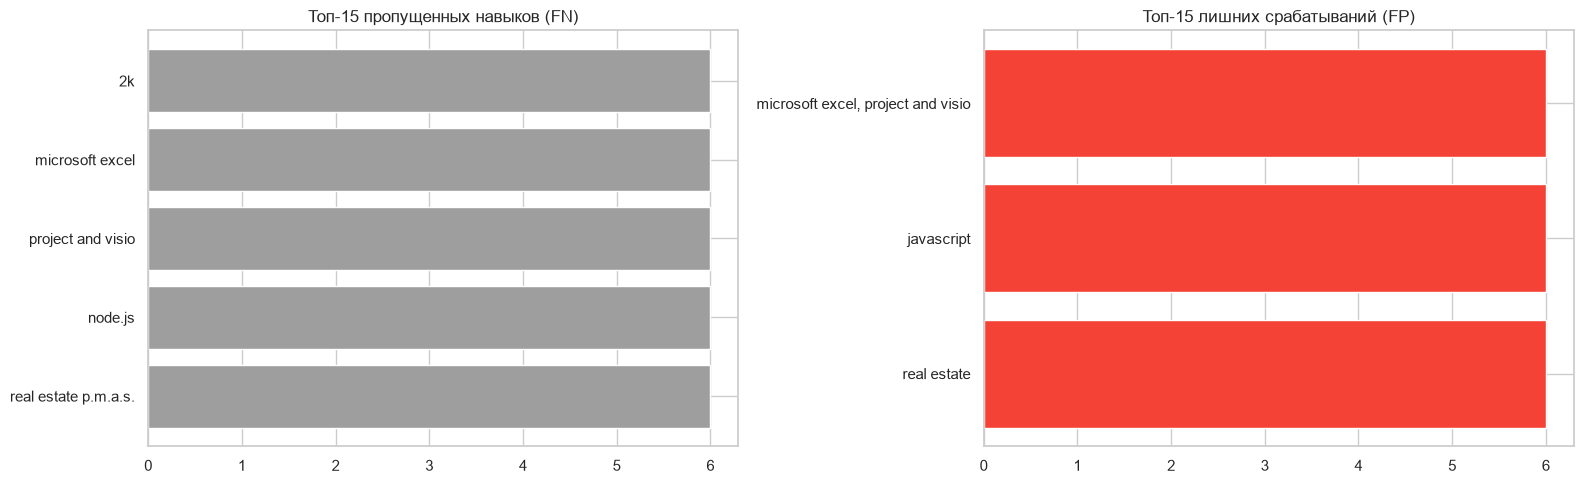

Примеры документов с ошибками:
  вход : 3d, accounting, Accountant, Accounts receivables, Adobe Illustrator, Adobe Photoshop, Pagemaker, Audio Editing, auditing, banking, book, Bud…
  FN   : ['2k']   FP: []
  вход : 3d, accounting, Accountant, Accounts receivables, Adobe Illustrator, Adobe Photoshop, Pagemaker, Audio Editing, auditing, banking, book, Bud…
  FN   : ['2k']   FP: []
  вход : Excellent communication techniques, Engineering standards expert, Complex problem solver, Advanced critical thinking, Microsoft Excel, Proje…
  FN   : ['microsoft excel', 'project and visio']   FP: ['microsoft excel, project and visio']
  вход : 3d, accounting, Accountant, Accounts receivables, Adobe Illustrator, Adobe Photoshop, Pagemaker, Audio Editing, auditing, banking, book, Bud…
  FN   : ['2k']   FP: []


In [10]:
vocab_freq = Counter(s for raw in vocab_rows["skills"].dropna() for s in parse_skills_gt(raw))
for raw in vocab_rows["related_skils_in_job"].dropna():
    for s in parse_skills_gt(raw):
        vocab_freq[s] += 1
pattern_skills = VOCAB_SKILLS | CURATED

fn_c, fp_c = res_main["fn_counter"], res_main["fp_counter"]
fn_oov   = sum(c for s, c in fn_c.items() if s not in pattern_skills)         # навыка нет в словаре вообще
fn_in_v  = sum(c for s, c in fn_c.items() if s in pattern_skills)             # навык в словаре, но не найден (проблема токенизации/совпадения)
print(f"Пропущено упоминаний (FN): {res_main['FN']}; из них навыка нет в словаре (OOV): {fn_oov} ({fn_oov / max(1, res_main['FN']):.0%}); "
      f"навык есть в словаре, но не найден: {fn_in_v}")
if fn_in_v:
    print("  примеры «есть в словаре, но не найден»:", [s for s, _ in fn_c.most_common() if s in pattern_skills][:10])

# recall по частоте навыка в vocab-части
def bucket(skill):
    f = vocab_freq.get(skill, 0)
    return "0 (не встречался)" if f == 0 else "1" if f == 1 else "2–4" if f < 5 else "5+"
tot, hit = Counter(), Counter()
for p, g in zip(preds_test, gold_test):
    for s in g:
        tot[bucket(s)] += 1
        hit[bucket(s)] += int(s in p)
order = ["0 (не встречался)", "1", "2–4", "5+"]
rec_b = pd.DataFrame({"упоминаний в test": [tot[b] for b in order], "найдено": [hit[b] for b in order]}, index=order)
rec_b["recall"] = rec_b["найдено"] / rec_b["упоминаний в test"].replace(0, np.nan)
display(rec_b.round(3).rename_axis("встречался в vocab-части (раз)"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, cnt, title, color in [(axes[0], fn_c, "Топ-15 пропущенных навыков (FN)", "#9E9E9E"),
                              (axes[1], fp_c, "Топ-15 лишних срабатываний (FP)", "#F44336")]:
    items = cnt.most_common(15)
    if items:
        ax.barh([i[0] for i in items][::-1], [i[1] for i in items][::-1], color=color)
    ax.set_title(title)
plt.tight_layout(); plt.show()

print("Примеры документов с ошибками:")
shown = 0
for txt, p, g in zip(ner_input(test_rows), preds_test, gold_test):
    if (g - p) or (p - g):
        print(f"  вход : {txt[:140]}…")
        print(f"  FN   : {sorted(g - p)[:6]}   FP: {sorted(p - g)[:6]}")
        shown += 1
        if shown == 4:
            break
if shown == 0:
    print("  (ошибок нет)")

## 6. Matching: TF-IDF обучается только на части `train`
Skill Overlap — доля требуемых навыков вакансии, найденных у кандидата. TF-IDF + cosine — сходство текстов. Векторизатор раньше обучался на **всех** 9 544 резюме; теперь — только на части `train` (она не пересекается ни с `vocab`, ни с `test`).

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize as sk_normalize

TFIDF_PARAMS = dict(ngram_range=(1, 2), stop_words='english', max_features=10000, sublinear_tf=True)

def skill_overlap_score(resume_skills, job_skills) -> dict:
    resume_set = {normalize_skill(s) for s in resume_skills}
    job_set = {normalize_skill(s) for s in job_skills}
    if not job_set:
        return {"score": 0.0, "matched": [], "missing": [], "extra": []}
    matched, missing, extra = resume_set & job_set, job_set - resume_set, resume_set - job_set
    return {"score": round(len(matched) / len(job_set), 3), "matched": sorted(matched),
            "missing": sorted(missing), "extra": sorted(extra)}

class ResumeJobMatcher:
    def __init__(self, **params):
        self.vectorizer = TfidfVectorizer(**(params or TFIDF_PARAMS))
    def fit(self, corpus):
        self.vectorizer.fit(corpus)
        return self
    def match(self, resume_text: str, job_description: str) -> float:
        vectors = self.vectorizer.transform([resume_text, job_description])
        return round(float(cosine_similarity(vectors[0], vectors[1])[0][0]), 4)

train_texts_all = df.loc[df["split"] == "train", "resume_text"].tolist()
matcher = ResumeJobMatcher().fit(train_texts_all)
print(f"Матчер обучен на {len(train_texts_all)} резюме части train ({len(matcher.vectorizer.vocabulary_)} терминов)")

Матчер обучен на 3728 резюме части train (10000 терминов)


## 7. Вспомогательные функции оценки (ранжирование внутри вакансии, поиск, время/память)
* **главная метрика — ранжирование кандидатов внутри вакансии**: для каждой вакансии из `test` считаем ρ Спирмена между сходством «резюме — вакансия» и `matched_score` её кандидатов, а также P@10 (доля верхней десятки по сходству, попавшая в лучшие 20% по `matched_score` этой вакансии); затем усредняем **по вакансиям**. Доверительные интервалы — bootstrap по вакансиям (резюме одной вакансии зависимы друг от друга, поэтому ресэмплировать нужно вакансии);
* поиск (вторично): Precision@k и MRR, релевантным считается документ-вакансия с тем же названием должности;
* ресурсы: время (`perf_counter`), пик памяти Python/NumPy (`tracemalloc`, отдельный проход, чтобы трассировка не искажала время) и прирост RSS процесса (видит и C-память: spaCy, torch).

In [12]:
from scipy.stats import spearmanr

def within_vacancy_ranking(sim, ms, groups, min_cands=None, top_frac=None, k=10):
    """Ранжирование кандидатов ВНУТРИ каждой вакансии (так исключается тривиальный эффект «разные вакансии — разные тексты»).
    sim — сходство «резюме — своя вакансия», ms — matched_score, groups — номер вакансии.
    Возвращает таблицу: одна строка = одна вакансия (n кандидатов, ρ Спирмена, P@k, доля «хороших» кандидатов = случайный уровень P@k)."""
    min_cands = MIN_CANDS_PER_VACANCY if min_cands is None else min_cands
    top_frac = TOP_FRAC if top_frac is None else top_frac
    sim, ms, groups = np.asarray(sim, dtype=float), np.asarray(ms, dtype=float), np.asarray(groups)
    rows = []
    for g in np.unique(groups):
        m = (groups == g) & ~np.isnan(ms) & ~np.isnan(sim)
        n = int(m.sum())
        if n < min_cands or np.ptp(sim[m]) == 0 or np.ptp(ms[m]) == 0:
            continue
        s, y = sim[m], ms[m]
        good = y >= np.quantile(y, 1 - top_frac)
        top = np.argsort(-s, kind="stable")[:min(k, n)]
        rows.append(dict(vacancy=g, n=n, rho=float(spearmanr(s, y).statistic), p_at_k=float(good[top].mean()), base=float(good.mean())))
    return pd.DataFrame(rows, columns=["vacancy", "n", "rho", "p_at_k", "base"])

def fmt_ci(ci):
    return "—" if (ci is None or np.isnan(np.asarray(ci, dtype=float)).any()) else f"[{ci[0]:+.3f}; {ci[1]:+.3f}]"

def rank_summary(tbl, n_boot=None, seed=SEED):
    """Среднее по вакансиям + 95% bootstrap CI (ресэмплируются ВАКАНСИИ)."""
    n_boot = n_boot or BOOTSTRAP
    if len(tbl) == 0:
        nan2 = (float("nan"), float("nan"))
        return dict(n_vac=0, rho=float("nan"), rho_ci=nan2, p10=float("nan"), p10_ci=nan2, base=float("nan"))
    rho, p = tbl["rho"].to_numpy(), tbl["p_at_k"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(tbl), (n_boot, len(tbl)))
    return dict(n_vac=int(len(tbl)), rho=float(rho.mean()), rho_ci=tuple(np.percentile(rho[idx].mean(1), [2.5, 97.5])),
                p10=float(p.mean()), p10_ci=tuple(np.percentile(p[idx].mean(1), [2.5, 97.5])), base=float(tbl["base"].mean()))

# контроль на синтетике: идеальный порядок даёт ρ = 1, случайный — ρ ≈ 0
_g = np.repeat([0, 1], 30); _ms = np.tile(np.arange(30, dtype=float), 2)
_t = within_vacancy_ranking(_ms, _ms, _g, min_cands=10, top_frac=0.2, k=10)
assert len(_t) == 2 and np.allclose(_t["rho"], 1.0) and np.allclose(_t["p_at_k"], 0.6) and np.allclose(_t["base"], 0.2)
_r = within_vacancy_ranking(np.random.default_rng(0).random(3000), np.tile(np.arange(30, dtype=float), 100), np.repeat(np.arange(100), 30), min_cands=10)
assert abs(_r["rho"].mean()) < 0.1, "для случайного сходства ρ должно быть ≈ 0"

def retrieval_metrics(S, REL, ks=(1, 5, 10)):
    order = np.argsort(-S, axis=1, kind="stable")
    rel_sorted = np.take_along_axis(REL, order, axis=1)
    out = {f"P@{k}": float(rel_sorted[:, :k].mean()) for k in ks}
    has = rel_sorted.any(axis=1)
    out["MRR"] = float(np.mean(np.where(has, 1.0 / (rel_sorted.argmax(axis=1) + 1), 0.0)))
    return out

_proc = psutil.Process()
def profile_run(fn, trace=True):
    """Возвращает (результат, секунды, пик tracemalloc MB | None, прирост RSS MB). Память меряется вторым проходом."""
    gc.collect()
    rss0 = _proc.memory_info().rss
    t0 = time.perf_counter(); out = fn(); dt = time.perf_counter() - t0
    drss = (_proc.memory_info().rss - rss0) / 2**20
    peak = None
    if trace:
        gc.collect(); tracemalloc.start(); fn(); peak = tracemalloc.get_traced_memory()[1] / 2**20; tracemalloc.stop()
    return out, dt, peak, drss

def sparse_mb(X):
    return (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 2**20 if hasattr(X, "indptr") else X.nbytes / 2**20

## 8. Стемминг vs лемматизация
Сравниваем **Porter** и **Snowball** (NLTK) со **spaCy-лемматизатором** (`en_core_web_md`, правила + POS-теги) на резюме частей `train` и `test` (часть `vocab` не используется). Токены: только буквенные, не стоп-слова, длиннее 1 символа.
Смотрим: (1) примеры, (2) размер словаря и «нечитаемые» формы, (3) склейки и недосклейки, (4) что происходит с названиями технологий, (5) скорость, (6) влияние на качество ранжирования кандидатов (ρ Спирмена между TF-IDF-сходством «резюме — вакансия» и `matched_score` внутри вакансии).

In [13]:
from nltk.stem import PorterStemmer, SnowballStemmer
porter, snowball = PorterStemmer(), SnowballStemmer("english")
nlp_lem = spacy.load(SPACY_MODEL, exclude=["ner", "parser"])      # tok2vec + tagger + attribute_ruler + lemmatizer

EXAMPLE_SENTENCES = [
    "Developed and deployed machine learning models, analyzing large databases and optimizing queries.",
    "Managed 5 engineers; the studies showed our pipelines were running better after the migrations.",
    "Experienced with Pandas, Kubernetes, Redis and Tableau; built dashboards for universities and universal services.",
    "Led analyses of data and operations, relying on statistics, libraries and APIs.",
]
rows = []
for doc in nlp_lem.pipe(EXAMPLE_SENTENCES):
    for t in doc:
        if t.is_alpha:
            w = t.lower_
            rows.append((w, t.pos_, porter.stem(w), snowball.stem(w), t.lemma_.lower()))
ex = pd.DataFrame(rows, columns=["слово", "POS", "Porter", "Snowball", "spaCy lemma"]).drop_duplicates("слово")
ex["стем ≠ лемма"] = (ex["Porter"] != ex["spaCy lemma"]) | (ex["Snowball"] != ex["spaCy lemma"])
display(ex[ex["стем ≠ лемма"] | (ex["слово"] != ex["spaCy lemma"])].reset_index(drop=True).head(45))

,слово,POS,Porter,Snowball,spaCy lemma,стем ≠ лемма
0,developed,VERB,develop,develop,develop,False
1,deployed,VERB,deploy,deploy,deploy,False
2,machine,NOUN,machin,machin,machine,True
3,learning,NOUN,learn,learn,learning,True
4,models,NOUN,model,model,model,False
5,analyzing,VERB,analyz,analyz,analyze,True
6,large,ADJ,larg,larg,large,True
7,databases,NOUN,databas,databas,database,True
8,optimizing,VERB,optim,optim,optimize,True
9,queries,NOUN,queri,queri,query,True


In [14]:
norm_rows = df[df["split"].isin(["train", "test"])]
if NORM_MAX_DOCS:
    norm_rows = norm_rows.head(NORM_MAX_DOCS)
n_all_tokens = 0
tok_lists, lem_lists = [], []
t0 = time.perf_counter()
for doc in nlp_lem.pipe(norm_rows["resume_text"].tolist(), batch_size=32):
    n_all_tokens += len(doc)
    toks = [t for t in doc if t.is_alpha and not t.is_stop and len(t) > 1]
    tok_lists.append([t.lower_ for t in toks])
    lem_lists.append([t.lemma_.lower() for t in toks])
t_spacy = time.perf_counter() - t0
flat = [w for l in tok_lists for w in l]
print(f"Документов: {len(norm_rows)}, токенов всего: {n_all_tokens}, после фильтра: {len(flat)}; spaCy (токенизация+теггер+лемматизатор): {t_spacy:.1f} с")

def stem_lists(stemmer, lists):
    cache, out = {}, []
    for l in lists:
        o = []
        for w in l:
            s = cache.get(w)
            if s is None:
                s = cache[w] = stemmer.stem(w)
            o.append(s)
        out.append(o)
    return out

NORM = {"raw": tok_lists, "porter": stem_lists(porter, tok_lists), "snowball": stem_lists(snowball, tok_lists), "lemma": lem_lists}

# скорость: стеммеры на выборке токенов (без кэша) vs полный spaCy-проход
sample = flat[:150_000]
def tok_per_s(stemmer):
    t = time.perf_counter(); [stemmer.stem(w) for w in sample]; return len(sample) / (time.perf_counter() - t)
nlp_tok = spacy.blank("en")
_sample_docs = norm_rows["resume_text"].tolist()[:500]
_n_tok = sum(len(d) for d in nlp_tok.pipe(_sample_docs))                      # заодно «прогрев»
_t = time.perf_counter(); _ = [d for d in nlp_tok.pipe(_sample_docs)]; tok_only = _n_tok / (time.perf_counter() - _t)
speed = pd.DataFrame({"токенов/с": {"только токенизация spaCy": tok_only, "Porter (на готовых токенах)": tok_per_s(porter),
                                     "Snowball (на готовых токенах)": tok_per_s(snowball), "spaCy: токенизация+теггер+лемматизатор": n_all_tokens / t_spacy}}).round(0)
display(speed)

Документов: 5761, токенов всего: 462841, после фильтра: 263691; spaCy (токенизация+теггер+лемматизатор): 39.5 с


,токенов/с
только токенизация spaCy,898114.0
Porter (на готовых токенах),37493.0
Snowball (на готовых токенах),61204.0
spaCy: токенизация+теггер+лемматизатор,11717.0


In [15]:
surface = Counter(flat)
surface_types = set(surface)
stats = []
for name, lists in NORM.items():
    types = {w for l in lists for w in l}
    cv2 = CountVectorizer(ngram_range=(2, 2), token_pattern=r"(?u)\b\w+\b", lowercase=False)
    cv2.fit([" ".join(l) for l in lists])
    stats.append({"нормализация": name, "типов (униграммы)": len(types),
                  "сжатие словаря vs raw": 1 - len(types) / len(surface_types),
                  "типов (биграммы)": len(cv2.vocabulary_),
                  "% типов, которых нет как слов в корпусе": len(types - surface_types) / len(types)})
    del cv2
stats = pd.DataFrame(stats).set_index("нормализация")
display(stats.round(3))

# склейки (несколько лемм → один стем) и недосклейки (одна лемма → несколько стемов)
lemma_of = defaultdict(Counter)
for tl, ll in zip(tok_lists, lem_lists):
    for w, l in zip(tl, ll):
        lemma_of[w][l] += 1
lemma_of = {w: c.most_common(1)[0][0] for w, c in lemma_of.items()}
stem_of = {w: porter.stem(w) for w in surface}
stem_freq, stem_lemmas, lemma_stems = Counter(), defaultdict(set), defaultdict(set)
for w, c in surface.items():
    stem_freq[stem_of[w]] += c
    stem_lemmas[stem_of[w]].add(lemma_of[w])
    lemma_stems[lemma_of[w]].add(stem_of[w])
over  = [(s, sorted(l)[:6], stem_freq[s]) for s, l in stem_lemmas.items() if len(l) >= 2]
over.sort(key=lambda x: -x[2])
lemma_freq = Counter()
for w, c in surface.items():
    lemma_freq[lemma_of[w]] += c
under = [(l, sorted(s), lemma_freq[l]) for l, s in lemma_stems.items() if len(s) >= 2]
under.sort(key=lambda x: -x[2])
print(f"Porter склеивает >=2 разных лемм в один стем у {len(over)} стемов; лемма делится на >=2 стема у {len(under)} лемм.\n")
print("Склейки (частые): стем ← леммы   [часть полезна: manager/management → manag; часть — ошибка смысла]")
for s, l, f in over[:12]:
    print(f"  {s:12s} ← {l}")
print("\nНедосклейки (одна лемма — несколько стемов): лемма → стемы")
for l, s, f in under[:10]:
    print(f"  {l:12s} → {s}")

,типов (униграммы),сжатие словаря vs raw,типов (биграммы),"% типов, которых нет как слов в корпусе"
нормализация,,,,
raw,2886,0.000,10564,0.000
porter,2207,0.235,10025,0.463
snowball,2211,0.234,10026,0.440
lemma,2698,0.065,10582,0.074


Porter склеивает >=2 разных лемм в один стем у 294 стемов; лемма делится на >=2 стема у 15 лемм.

Склейки (частые): стем ← леммы   [часть полезна: manager/management → manag; часть — ошибка смысла]
  learn        ← ['learn', 'learning']
  manag        ← ['manage', 'management', 'manager', 'managing']
  machin       ← ['machine', 'machining']
  account      ← ['account', 'accountable', 'accountant', 'accounting']
  process      ← ['process', 'processing']
  develop      ← ['develop', 'developer', 'development']
  skill        ← ['skill', 'skilled']
  engin        ← ['engineer', 'engineering']
  softwar      ← ['software', 'softwares']
  financi      ← ['financial', 'financials']
  excel        ← ['excel', 'excellence', 'excellent']
  analyt       ← ['analytical', 'analytics']

Недосклейки (одна лемма — несколько стемов): лемма → стемы
  analysis     → ['analys', 'analysi']
  experience   → ['experi', 'experienc']
  deep         → ['deep', 'deeper']
  write        → ['write', 'written']


In [16]:
# что происходит с названиями технологий (однословные навыки из vocab-части)
vocab_freq_all = Counter(s for raw in vocab_rows["skills"].dropna() for s in parse_skills_gt(raw))
single = [s for s, _ in vocab_freq_all.most_common() if re.fullmatch(r"[a-z]{3,}", s)][:300]
ch_porter  = {s: porter.stem(s) for s in single if porter.stem(s) != s}
ch_snow    = {s: snowball.stem(s) for s in single if snowball.stem(s) != s}
ch_lemma = {}
for s, d in zip(single, nlp_lem.pipe([f"Experience with {s} and other tools." for s in single])):
    cand = [t for t in d if t.lower_ == s]
    if cand and cand[0].lemma_.lower() != s:
        ch_lemma[s] = cand[0].lemma_.lower()
tech = pd.DataFrame({"Porter": [len(ch_porter) / len(single)], "Snowball": [len(ch_snow) / len(single)],
                     "spaCy lemma": [len(ch_lemma) / len(single)]}, index=[f"доля из топ-{len(single)} однословных навыков, которые меняются"]).T
display(tech.round(3))
print("Примеры искажения названий технологий:")
print("  Porter  :", dict(list(ch_porter.items())[:10]))
print("  Snowball:", dict(list(ch_snow.items())[:10]))
print("  lemma   :", dict(list(ch_lemma.items())[:10]))

,"доля из топ-300 однословных навыков, которые меняются"
Porter,0.603
Snowball,0.587
spaCy lemma,0.213


Примеры искажения названий технологий:
  Porter  : {'sales': 'sale', 'documentation': 'document', 'accounting': 'account', 'processes': 'process', 'clients': 'client', 'quality': 'qualiti', 'inventory': 'inventori', 'contracts': 'contract', 'financial': 'financi', 'policies': 'polici'}
  Snowball: {'sales': 'sale', 'documentation': 'document', 'accounting': 'account', 'processes': 'process', 'clients': 'client', 'quality': 'qualiti', 'inventory': 'inventori', 'contracts': 'contract', 'financial': 'financi', 'policies': 'polici'}
  lemma   : {'sales': 'sale', 'processes': 'process', 'clients': 'client', 'contracts': 'contract', 'policies': 'policy', 'materials': 'material', 'quickbooks': 'quickbook', 'windows': 'window', 'pandas': 'panda', 'budgets': 'budget'}


,признаков,вакансий,ρ внутри вакансии,ρ 95% CI,P@10 (топ-20%),P@10 случайно
нормализация,,,,,,
raw,10000,6,0.297,[+0.174; +0.398],0.650,0.289
porter,10000,6,0.338,[+0.245; +0.413],0.617,0.289
snowball,10000,6,0.338,[+0.245; +0.413],0.617,0.289
lemma,10000,6,0.294,[+0.172; +0.399],0.683,0.289


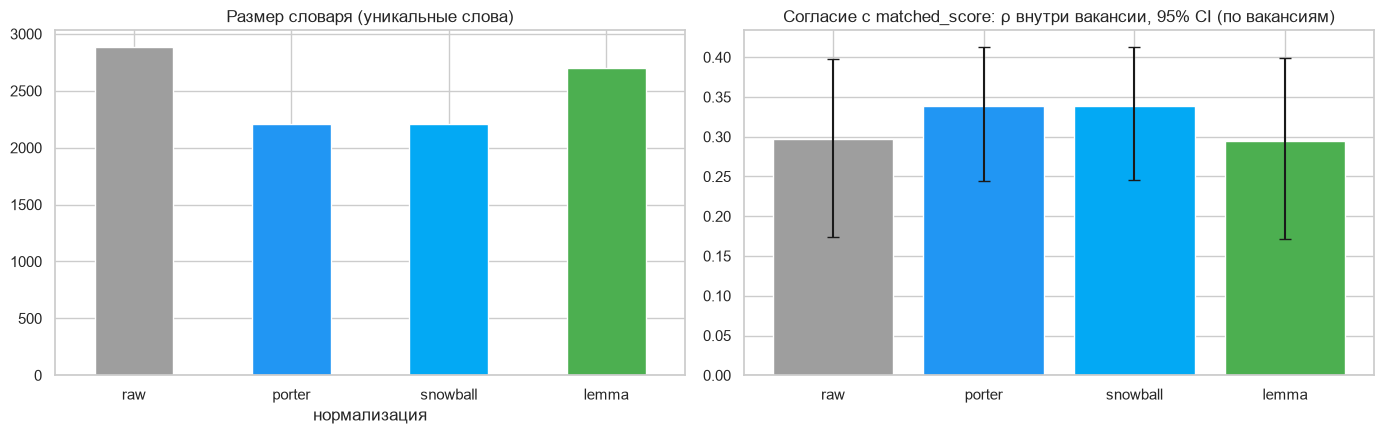

In [17]:
# влияние на качество: TF-IDF (1–2-граммы), fit на train → сходство «резюме — своя вакансия» в test → ρ Спирмена с matched_score внутри вакансии
split_v = norm_rows["split"].to_numpy()
m_train_all, m_test = split_v == "train", split_v == "test"
test_n = norm_rows[m_test]
assert m_train_all.sum() > 0 and len(test_n) > 0, "Нет резюме в train/test"

uniq_jobs = test_n["job_text"].drop_duplicates().tolist()                    # вакансии нормализуем тем же способом, что и резюме
job_pos = {t: i for i, t in enumerate(uniq_jobs)}
job_lists = {"raw": [], "lemma": []}
for doc in nlp_lem.pipe(uniq_jobs, batch_size=32):
    toks = [t for t in doc if t.is_alpha and not t.is_stop and len(t) > 1]
    job_lists["raw"].append([t.lower_ for t in toks]); job_lists["lemma"].append([t.lemma_.lower() for t in toks])
job_lists["porter"], job_lists["snowball"] = stem_lists(porter, job_lists["raw"]), stem_lists(snowball, job_lists["raw"])
own_job = test_n["job_text"].map(job_pos).to_numpy()                          # номер вакансии = группа для ранжирования
ms_n = test_n["matched_score"].to_numpy(dtype=float)

norm_eval, norm_ci = [], {}
for name, lists in NORM.items():
    texts = np.array([" ".join(l) for l in lists], dtype=object)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=10000).fit(texts[m_train_all])
    Xr = vec.transform(texts[m_test])
    Xj = vec.transform([" ".join(l) for l in job_lists[name]])
    own = np.asarray(Xr.multiply(Xj[own_job]).sum(1)).ravel()                 # векторы L2-нормированы → скалярное произведение = cosine
    rk = rank_summary(within_vacancy_ranking(own, ms_n, own_job))
    norm_ci[name] = rk["rho_ci"]
    norm_eval.append({"нормализация": name, "признаков": len(vec.vocabulary_), "вакансий": rk["n_vac"], "ρ внутри вакансии": rk["rho"],
                      "ρ 95% CI": fmt_ci(rk["rho_ci"]), "P@10 (топ-20%)": rk["p10"], "P@10 случайно": rk["base"]})
norm_eval = pd.DataFrame(norm_eval).set_index("нормализация")
display(norm_eval.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
stats["типов (униграммы)"].plot(kind="bar", ax=axes[0], color=["#9E9E9E", "#2196F3", "#03A9F4", "#4CAF50"]); axes[0].set_title("Размер словаря (уникальные слова)"); axes[0].tick_params(axis="x", rotation=0)
rho_v = norm_eval["ρ внутри вакансии"].to_numpy(dtype=float)
lo_v = np.array([norm_ci[n][0] for n in norm_eval.index]); hi_v = np.array([norm_ci[n][1] for n in norm_eval.index])
axes[1].bar(list(norm_eval.index), rho_v, yerr=np.clip(np.vstack([rho_v - lo_v, hi_v - rho_v]), 0, None), capsize=4, color=["#9E9E9E", "#2196F3", "#03A9F4", "#4CAF50"])
axes[1].axhline(0, color="k", lw=0.8); axes[1].set_title("Согласие с matched_score: ρ внутри вакансии, 95% CI (по вакансиям)"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [18]:
# автоматические выводы (числа подставляются из этого запуска)
_rho = norm_eval["ρ внутри вакансии"].astype(float)
print("ВЫВОДЫ по нормализации (посчитаны в этом запуске):")
print(f"• Размер словаря: raw {stats.loc['raw','типов (униграммы)']} → lemma {stats.loc['lemma','типов (униграммы)']} "
      f"({stats.loc['lemma','сжатие словаря vs raw']:.0%}), Porter {stats.loc['porter','типов (униграммы)']} ({stats.loc['porter','сжатие словаря vs raw']:.0%}), "
      f"Snowball {stats.loc['snowball','типов (униграммы)']} ({stats.loc['snowball','сжатие словаря vs raw']:.0%}).")
print(f"• «Нечитаемые» формы (не встречаются как слова корпуса): Porter {stats.loc['porter'].iloc[-1]:.0%}, Snowball {stats.loc['snowball'].iloc[-1]:.0%}, лемматизация {stats.loc['lemma'].iloc[-1]:.0%}.")
print(f"• Названия технологий искажаются: Porter {tech.loc['Porter'].iloc[0]:.0%}, Snowball {tech.loc['Snowball'].iloc[0]:.0%}, лемматизатор {tech.loc['spaCy lemma'].iloc[0]:.0%} однословных навыков.")
print(f"• Скорость: стемминг ~{speed.loc['Porter (на готовых токенах)'].iloc[0] / speed.loc['spaCy: токенизация+теггер+лемматизатор'].iloc[0]:.0f}× быстрее полного spaCy-прохода на токен (но токенизацию стеммеру тоже нужно кому-то поручить).")
if _rho.notna().any():
    best_norm = _rho.idxmax(); lo_b, hi_b = norm_ci[best_norm]
    others_inside = [n for n in norm_eval.index if n != best_norm and lo_b <= _rho[n] <= hi_b]
    print(f"• Качество: наибольший ρ внутри вакансии у «{best_norm}» ({_rho[best_norm]:+.3f}); "
          + (f"ещё {others_inside} внутри его 95% CI → различия статистически неразличимы." if others_inside else "остальные варианты вне его 95% CI."))
    if lo_b <= 0 <= hi_b:
        print("  ⚠ Доверительный интервал лучшего варианта включает 0: ни один вариант нормализации не показывает связи сходства с matched_score.")
else:
    print("• Качество: нет вакансий с достаточным числом кандидатов (см. MIN_CANDS_PER_VACANCY) — ρ не посчитан.")
max_dist = float(tech.iloc[:, 0].max())
print("\nРЕШЕНИЕ для проекта:")
if max_dist >= 0.05:
    print(f"  словарный поиск навыков (EntityRuler, LOWER) оставляем БЕЗ стемминга/лемматизации: нормализация меняет до {max_dist:.0%} названий технологий, "
          "и словарные паттерны перестали бы совпадать с текстом.")
else:
    print(f"  названия технологий почти не искажаются (макс. {max_dist:.0%}), но словарный поиск всё равно проще и надёжнее оставить на LOWER без нормализации.")
print("  Нормализацию стоит добавлять только в «мешочные» признаки (TF-IDF) и только если она улучшает ρ внутри вакансии вне доверительного интервала "
      "(см. строку «Качество» выше); иначе выигрыш — лишь в размере словаря, а не в качестве.")

ВЫВОДЫ по нормализации (посчитаны в этом запуске):
• Размер словаря: raw 2886 → lemma 2698 (7%), Porter 2207 (24%), Snowball 2211 (23%).
• «Нечитаемые» формы (не встречаются как слова корпуса): Porter 46%, Snowball 44%, лемматизация 7%.
• Названия технологий искажаются: Porter 60%, Snowball 59%, лемматизатор 21% однословных навыков.
• Скорость: стемминг ~3× быстрее полного spaCy-прохода на токен (но токенизацию стеммеру тоже нужно кому-то поручить).
• Качество: наибольший ρ внутри вакансии у «snowball» (+0.338); ещё ['raw', 'porter', 'lemma'] внутри его 95% CI → различия статистически неразличимы.

РЕШЕНИЕ для проекта:
  словарный поиск навыков (EntityRuler, LOWER) оставляем БЕЗ стемминга/лемматизации: нормализация меняет до 60% названий технологий, и словарные паттерны перестали бы совпадать с текстом.
  Нормализацию стоит добавлять только в «мешочные» признаки (TF-IDF) и только если она улучшает ρ внутри вакансии вне доверительного интервала (см. строку «Качество» выше); иначе выигры

## 9. Частотный анализ n-грамм (униграммы, биграммы, триграммы)
Корпус — резюме части `train` (нижний регистр; токенизатор сохраняет `c++`, `node.js`, `ci/cd`, `scikit-learn`). Стоп-слова **не** удаляются до построения n-грамм (иначе «experience in python» превращается в ложное «experience python»); вместо этого отбрасываются n-граммы, которые начинаются или заканчиваются стоп-словом. Частота считается двумя способами: **TF** (всего вхождений) и **DF** (в скольких резюме встречается) — для резюме DF надёжнее, потому что один кандидат может многократно повторять слово.

1-граммы: типов     3,189  | после фильтра стоп-слов     3,057  | вхождений    201,910
2-граммы: типов    12,024  | после фильтра стоп-слов     9,005  | вхождений    198,182
3-граммы: типов    15,570  | после фильтра стоп-слов    11,607  | вхождений    194,454


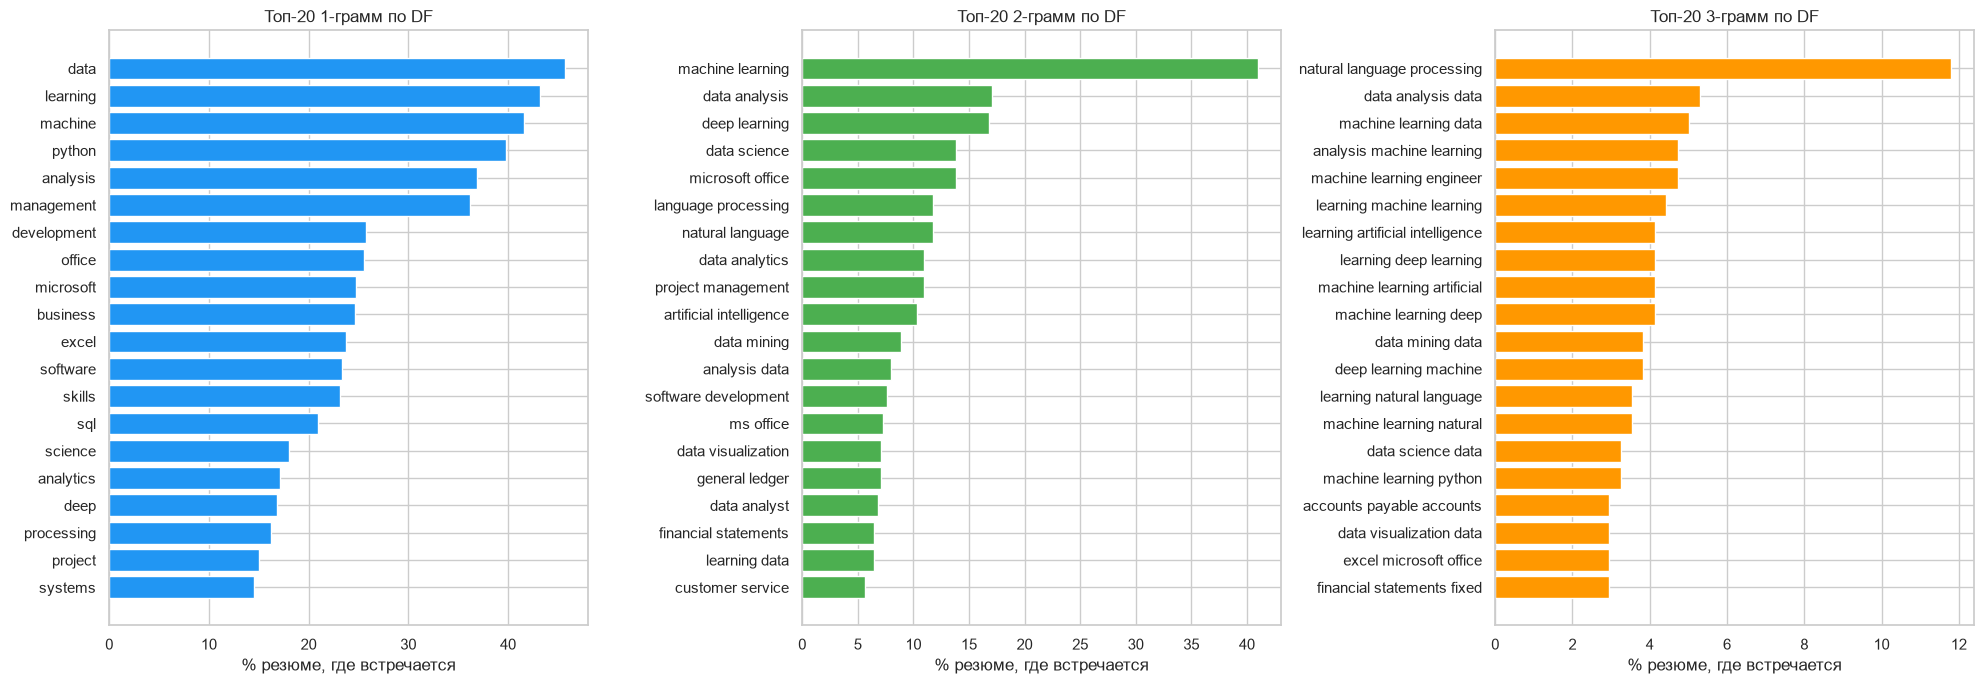

,n-грамма,DF (резюме),DF %,TF (вхождений),навык из словаря
0,machine learning,1529,41.0,2288,True
1,deep learning,627,16.8,715,True
2,data analysis,638,17.1,638,True
3,data science,517,13.9,605,True
4,microsoft office,517,13.9,561,True
5,language processing,440,11.8,517,False
6,natural language,440,11.8,517,False
7,data analytics,407,10.9,440,True
8,project management,407,10.9,440,True
9,artificial intelligence,385,10.3,429,True


In [19]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP
TOKEN_PAT = r"(?u)[a-zA-Z][a-zA-Z0-9+#]*(?:[./\-][a-zA-Z0-9+#]+)*"
train_mask_ng = (df["split"] == "train").to_numpy()
ng_texts = df.loc[train_mask_ng, "resume_text"].str.lower().tolist()
ng_labels = df.loc[train_mask_ng, "label"].to_numpy(dtype=object)
SKILL_SET = VOCAB_SKILLS | CURATED

NG = {}
for n in (1, 2, 3):
    cv = CountVectorizer(ngram_range=(n, n), token_pattern=TOKEN_PAT, lowercase=True, dtype=np.int32)
    X = cv.fit_transform(ng_texts)
    terms = cv.get_feature_names_out()
    tf = np.asarray(X.sum(0)).ravel()
    dfc = np.asarray((X > 0).sum(0)).ravel()
    keep = np.array([not ({t.split()[0], t.split()[-1]} & STOP) for t in terms])
    NG[n] = dict(X=X, terms=terms, tf=tf, df=dfc, keep=keep)
    del cv
    print(f"{n}-граммы: типов {len(terms):>9,}  | после фильтра стоп-слов {keep.sum():>9,}  | вхождений {tf.sum():>10,}")
N_DOCS_NG = len(ng_texts)

def top_table(n, by="df", k=20):
    d = NG[n]
    idx = np.where(d["keep"])[0]
    idx = idx[np.argsort(-d[by][idx], kind="stable")][:k]
    return pd.DataFrame({"n-грамма": d["terms"][idx], "DF (резюме)": d["df"][idx], "DF %": 100 * d["df"][idx] / N_DOCS_NG,
                         "TF (вхождений)": d["tf"][idx], "навык из словаря": [t in SKILL_SET for t in d["terms"][idx]]})

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
for ax, n, color in zip(axes, (1, 2, 3), ("#2196F3", "#4CAF50", "#FF9800")):
    t = top_table(n, "df", 20)
    ax.barh(t["n-грамма"][::-1], t["DF %"][::-1], color=color)
    ax.set_title(f"Топ-20 {n}-грамм по DF"); ax.set_xlabel("% резюме, где встречается")
plt.tight_layout(); plt.show()
display(top_table(2, "tf", 15).round(1))

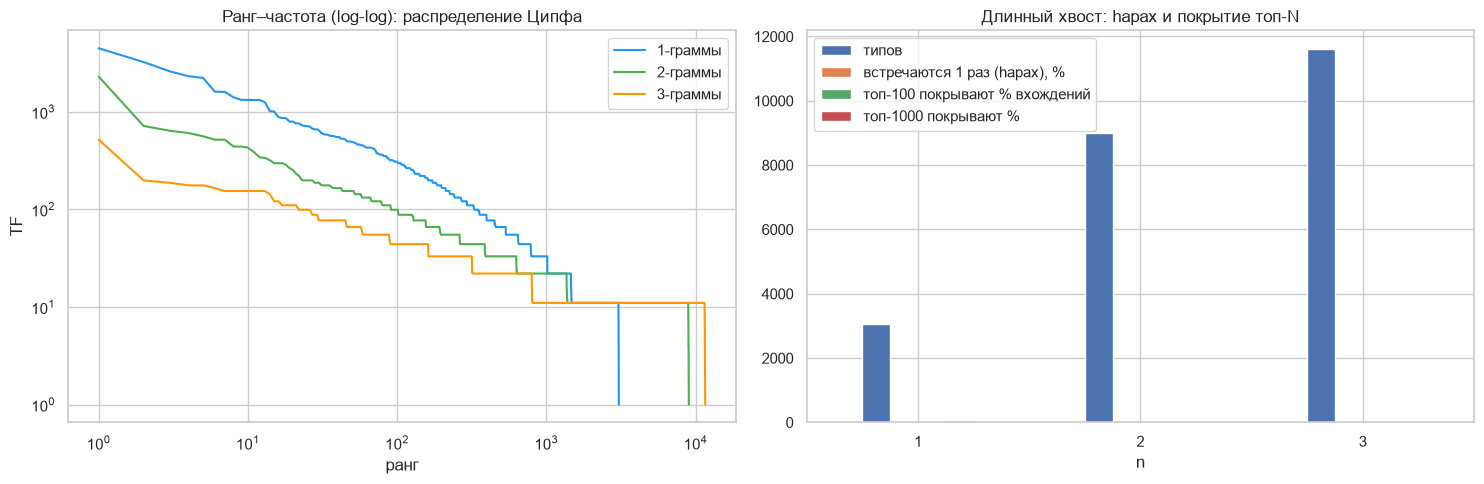

,типов,"встречаются 1 раз (hapax), %",топ-100 покрывают % вхождений,топ-1000 покрывают %
n,,,,
1,3057,0.1,40.4,83.8
2,9005,0.2,14.8,37.1
3,11607,0.3,5.8,20.1


In [20]:
# закон Ципфа (ранг–частота) и «длинный хвост»
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for n, color in zip((1, 2, 3), ("#2196F3", "#4CAF50", "#FF9800")):
    d = NG[n]; f = np.sort(d["tf"][d["keep"]])[::-1]
    axes[0].loglog(np.arange(1, len(f) + 1), f, color=color, label=f"{n}-граммы")
axes[0].set_title("Ранг–частота (log-log): распределение Ципфа"); axes[0].set_xlabel("ранг"); axes[0].set_ylabel("TF"); axes[0].legend()

tail = []
for n in (1, 2, 3):
    d = NG[n]; f = np.sort(d["tf"][d["keep"]])[::-1]
    tail.append({"n": n, "типов": len(f), "встречаются 1 раз (hapax), %": 100 * (f == 1).mean(),
                 "топ-100 покрывают % вхождений": 100 * f[:100].sum() / f.sum(), "топ-1000 покрывают %": 100 * f[:1000].sum() / f.sum()})
tail = pd.DataFrame(tail).set_index("n")
tail.round(1).plot(kind="bar", ax=axes[1]); axes[1].set_title("Длинный хвост: hapax и покрытие топ-N"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
display(tail.round(1))

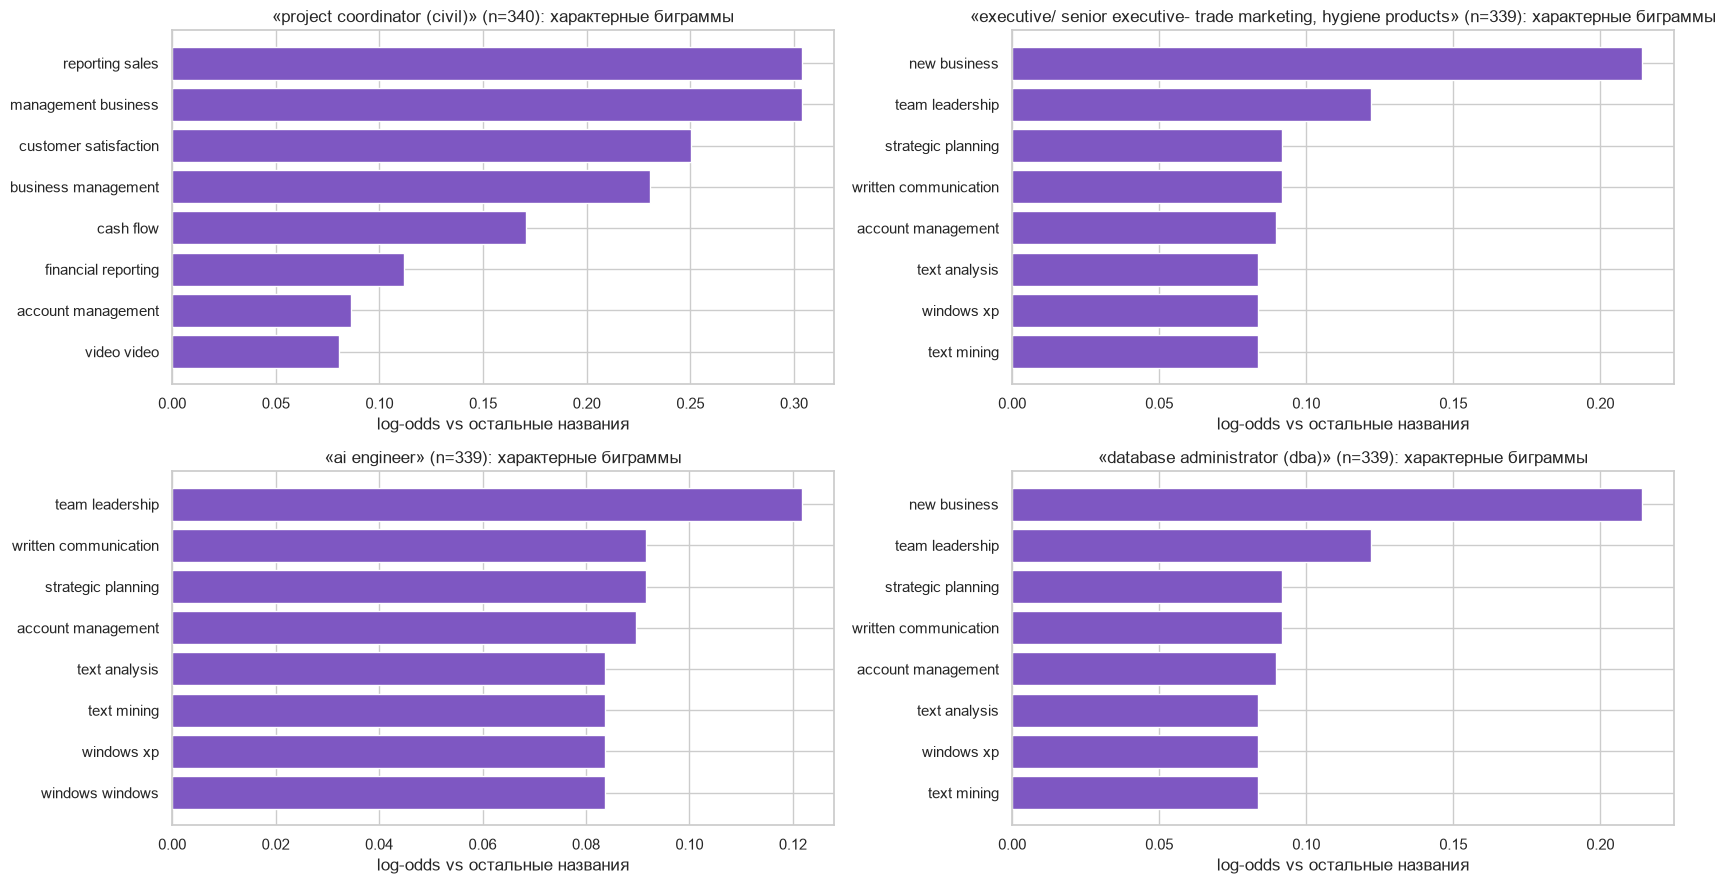

In [21]:
# характерные биграммы по названиям вакансий (описательно, только train; сглаженное log-odds, DF внутри названия vs остальные)
X2b = (NG[2]["X"] > 0).tocsr()
keep2, terms2 = NG[2]["keep"], NG[2]["terms"]
top_classes = [c for c, _ in Counter(l for l in ng_labels if l).most_common(4)]
fig, axes = plt.subplots(2, 2, figsize=(17, 9)); axes = axes.ravel()
distinct = {}
for ax, c in zip(axes, top_classes):
    m = ng_labels == c
    nc, nr = m.sum(), (~m).sum()
    dc = np.asarray(X2b[m].sum(0)).ravel(); dr = np.asarray(X2b[~m].sum(0)).ravel()
    a = 0.5
    lo = np.log((dc + a) / (nc - dc + a)) - np.log((dr + a) / (nr - dr + a))
    lo[~keep2 | (dc < 5)] = -np.inf
    idx = np.argsort(-lo)[:8]
    distinct[c] = [(terms2[i], int(dc[i]), int(dr[i])) for i in idx if np.isfinite(lo[i])]
    ax.barh([terms2[i] for i in idx][::-1], [lo[i] for i in idx][::-1], color="#7E57C2")
    ax.set_title(f"«{c}» (n={nc}): характерные биграммы"); ax.set_xlabel("log-odds vs остальные названия")
plt.tight_layout(); plt.show()

In [22]:
# PMI: «устойчивые словосочетания» против просто частых пар; повторы внутри резюме (TF/DF)
uni = dict(zip(NG[1]["terms"], NG[1]["tf"])); N1, N2 = NG[1]["tf"].sum(), NG[2]["tf"].sum()
b = NG[2]; sel = np.where(b["keep"] & (b["tf"] >= 15))[0]
pmi = np.array([np.log2((b["tf"][i] / N2) / ((uni.get(b["terms"][i].split()[0], 1) / N1) * (uni.get(b["terms"][i].split()[1], 1) / N1))) for i in sel])
pmi_tbl = pd.DataFrame({"биграмма": b["terms"][sel], "TF": b["tf"][sel], "PMI": pmi, "навык из словаря": [t in SKILL_SET for t in b["terms"][sel]]})
print("Топ-12 биграмм по PMI (TF >= 15):"); display(pmi_tbl.sort_values("PMI", ascending=False).head(12).round(2).reset_index(drop=True))

u = NG[1]; sel1 = np.where(u["keep"] & (u["df"] >= 20))[0]
rep = pd.DataFrame({"слово": u["terms"][sel1], "TF": u["tf"][sel1], "DF": u["df"][sel1], "TF/DF": u["tf"][sel1] / u["df"][sel1]})
print("\nСлова, которые резюме повторяют чаще всего (высокий TF/DF):"); display(rep.sort_values("TF/DF", ascending=False).head(8).round(2).reset_index(drop=True))

Топ-12 биграмм по PMI (TF >= 15):


,биграмма,TF,PMI,навык из словаря
0,random forest,22,13.19,True
1,recently graduated,22,13.19,False
2,originated interfaces,22,13.19,False
3,reduced costs,22,13.19,False
4,p l,22,13.19,False
5,forest xgboost,22,13.19,False
6,trouble shooting,22,13.19,True
7,travel arrangements,22,12.95,True
8,signal generators,22,12.61,True
9,air force,22,12.61,True



Слова, которые резюме повторяют чаще всего (высокий TF/DF):


,слово,TF,DF,TF/DF
0,trained,88,22,4.00
1,platforms,77,22,3.50
2,data,4466,1705,2.62
3,financial,1251,486,2.57
4,mortgage,55,22,2.50
5,skill,92,37,2.49
6,test,363,165,2.20
7,accounting,1003,475,2.11


In [23]:
# автоматическая интерпретация (числа из этого запуска)
t1, t2, t3 = top_table(1, "df", 30), top_table(2, "df", 30), top_table(3, "df", 30)
print("ИНТЕРПРЕТАЦИЯ:")
for n, t in ((1, t1), (2, t2), (3, t3)):
    sk = t["навык из словаря"].mean()
    generic = t.loc[~t["навык из словаря"], "n-грамма"].head(6).tolist()
    print(f"• {n}-граммы: среди топ-30 по DF {sk:.0%} — навыки из словаря; остальное — общие/служебные обороты: {generic}")
h = [tail.loc[n, 'встречаются 1 раз (hapax), %'] for n in (1, 2, 3)]
print(f"• Распределение Ципфа: доля n-грамм, встречающихся ровно один раз (hapax): {h[0]:.0f}% (униграммы) → {h[1]:.0f}% (биграммы) → {h[2]:.0f}% (триграммы). "
      "Чем длиннее n-грамма, тем разреженнее признак — это довод за ограничение (1,2) и за порог min_df в TF-IDF.")
print(f"• Топ-100 биграмм покрывают лишь {tail.loc[2, 'топ-100 покрывают % вхождений']:.0f}% всех вхождений: словарь навыков в тексте тоже имеет длинный хвост → EntityRuler с фиксированным словарём всегда будет упираться в OOV.")
hi_pmi = pmi_tbl.sort_values("PMI", ascending=False).head(12)
print(f"• Среди 12 биграмм с наибольшим PMI навыками из словаря являются {hi_pmi['навык из словаря'].mean():.0%}; "
      "PMI сильнее выделяет устойчивые словосочетания, чем чистая частота (сравните с таблицей топ-биграмм по TF выше).")
for c, lst in distinct.items():
    print(f"• «{c}»: " + ", ".join(t for t, _, _ in lst[:5]))
print("  Если характерные n-граммы названия вакансии — профессиональные термины, то такие вакансии различимы по лексике; "
      "если среди них много общих фраз, их тексты похожи (это важно помнить при чтении раздела 10b про «семейства» резюме).")

ИНТЕРПРЕТАЦИЯ:
• 1-граммы: среди топ-30 по DF 67% — навыки из словаря; остальное — общие/служебные обороты: ['data', 'learning', 'machine', 'business', 'deep', 'systems']
• 2-граммы: среди топ-30 по DF 77% — навыки из словаря; остальное — общие/служебные обороты: ['language processing', 'natural language', 'analysis data', 'learning data', 'analytics data', 'financial financial']
• 3-граммы: среди топ-30 по DF 10% — навыки из словаря; остальное — общие/служебные обороты: ['data analysis data', 'machine learning data', 'analysis machine learning', 'learning machine learning', 'learning artificial intelligence', 'learning deep learning']
• Распределение Ципфа: доля n-грамм, встречающихся ровно один раз (hapax): 0% (униграммы) → 0% (биграммы) → 0% (триграммы). Чем длиннее n-грамма, тем разреженнее признак — это довод за ограничение (1,2) и за порог min_df в TF-IDF.
• Топ-100 биграмм покрывают лишь 15% всех вхождений: словарь навыков в тексте тоже имеет длинный хвост → EntityRuler с фиксир

## 10. Сравнение представлений: baseline, Bag-of-Words, TF-IDF, эмбеддинги
Одно и то же разбиение **по вакансиям**, один и тот же вход (`RESUME_FIELDS`) и один и тот же эталон — `matched_score` из датасета. Обучаемых классификаторов здесь нет: сравниваются сами представления через сходство «резюме — вакансия».

| Представление | Описание |
|---|---|
| **Baseline** | случайный порядок |
| **Skill-overlap** | бинарный вектор навыков, найденных EntityRuler; сходство — формула продукта (доля навыков вакансии, найденных в резюме) |
| **BoW** | CountVectorizer (1–2-граммы, стоп-слова, 10 000 признаков), L2-нормировка счётчиков |
| **TF-IDF** | тот самый векторизатор, что сохраняется в `tfidf.pkl` (обучен на всех резюме `train`) |
| **spaCy-эмбеддинги** | среднее статических векторов `en_core_web_md` (300-d) по значимым словам |
| **Sentence-BERT** | `all-MiniLM-L6-v2` (если установлен `sentence-transformers` и есть доступ к модели; иначе пропускается) |

**Главная постановка — ранжирование кандидатов внутри вакансии.** Для каждой вакансии из `test` (не меньше `MIN_CANDS_PER_VACANCY` резюме с `matched_score`) считаем ρ Спирмена между сходством «резюме — вакансия» и `matched_score` и P@10 (доля верхней десятки кандидатов, попавшая в лучшие 20% по `matched_score`); затем усредняем по вакансиям. Случайный порядок даёт ρ ≈ 0 и P@10 ≈ доле «хороших» кандидатов (≈ 0.2). 95% CI — bootstrap по вакансиям.

**Вторично — поиск вакансии:** запрос — резюме из `test`, коллекция — уникальные вакансии из `test`; релевантна вакансия с тем же названием (Precision@1/5/10, MRR). Это не оценка качества matching, а проверка «можно ли угадать, для какой вакансии написано резюме»; такая метрика чувствительна к утечке (раздел 10b).

**Классификация «резюме → название вакансии» убрана:** при разбиении по вакансиям названия из `test` не встречаются в `train`, а при разбиении по строкам Accuracy ≈ 100% ничего не говорит о качестве (раздел 10b).

**Ресурсы**: время обучения/кодирования (с), задержка на документ (мс), пик памяти Python (`tracemalloc`, MB), прирост RSS процесса (MB), размер признаков и модели.

In [24]:
from scipy.sparse import csr_matrix
from scipy.stats import spearmanr

tr = df[df["split"] == "train"]
te = df[df["split"] == "test"]
assert len(tr) and len(te), "Нет резюме в train/test"
y_te = te["label"].to_numpy(dtype=object)
fit_texts, tr_texts, te_texts = train_texts_all, tr["resume_text"].tolist(), te["resume_text"].tolist()

pool = te.drop_duplicates(["job_text", "label"])                       # коллекция вакансий = уникальные вакансии test
pool_texts, pool_labels = pool["job_text"].tolist(), pool["label"].to_numpy(dtype=object)
_pidx = {(t, l): i for i, (t, l) in enumerate(zip(pool["job_text"], pool["label"]))}
own_idx = np.array([_pidx[(t, l)] for t, l in zip(te["job_text"], te["label"])])   # номер «своей» вакансии = группа для ранжирования
REL = y_te[:, None] == pool_labels[None, :]
ms_te = te["matched_score"].to_numpy(dtype=float)

_cnt = np.bincount(own_idx[~np.isnan(ms_te)], minlength=len(pool))
print(f"train: {len(tr)} резюме | test: {len(te)} резюме | вакансий в test: {len(pool)} | "
      f"кандидатов на вакансию (с matched_score): медиана {int(np.median(_cnt))}, min {_cnt.min()}, max {_cnt.max()}")
print(f"Вакансий для оценки ранжирования (≥ {MIN_CANDS_PER_VACANCY} кандидатов): {(_cnt >= MIN_CANDS_PER_VACANCY).sum()} из {len(pool)} "
      f"| релевантных вакансий на запрос в поиске в среднем: {REL.sum(1).mean():.1f}")
if (_cnt >= MIN_CANDS_PER_VACANCY).sum() < 5:
    print("⚠ Мало вакансий с достаточным числом кандидатов: ρ будет ненадёжным. Уменьшите MIN_CANDS_PER_VACANCY или увеличьте долю test в SPLIT_FRACTIONS.")

train: 3728 резюме | test: 2033 резюме | вакансий в test: 6 | кандидатов на вакансию (с matched_score): медиана 339, min 338, max 340
Вакансий для оценки ранжирования (≥ 10 кандидатов): 6 из 6 | релевантных вакансий на запрос в поиске в среднем: 1.0


In [25]:
class SparseRep:
    kind = "sparse"
    def __init__(self, name, make, l2=False, trace=True):
        self.name, self.make, self.l2, self.trace = name, make, l2, trace
    def fit(self, texts):
        self.v = self.make().fit(texts); return self
    def encode(self, texts):
        X = self.v.transform(texts)
        return sk_normalize(X) if self.l2 else X
    def similarity(self, Xq, Xp):
        return cosine_similarity(Xq, Xp)
    def dim(self): return len(self.v.vocabulary_)
    def model_mb(self):
        if hasattr(self.v, "stop_words_"):
            self.v.stop_words_ = None          # служебный атрибут: список отброшенных термов, сильно раздувает pickle
        return len(pickle.dumps(self.v)) / 2**20

class SpacyMeanRep:
    kind = "dense"
    def __init__(self, name="spaCy-эмбеддинги (en_core_web_md, mean)", trace=True):
        self.name, self.trace = name, trace
        self.nlp = spacy.load(SPACY_MODEL, exclude=["tok2vec", "tagger", "parser", "attribute_ruler", "lemmatizer", "ner"])
        self._dim = self.nlp.vocab.vectors_length
    def fit(self, texts): return self
    def encode(self, texts):
        out = np.zeros((len(texts), self._dim), dtype=np.float32)
        for i, doc in enumerate(self.nlp.pipe(texts, batch_size=64)):
            vs = [t.vector for t in doc if t.is_alpha and not t.is_stop and t.has_vector]
            if vs:
                out[i] = np.mean(vs, axis=0)
        n = np.linalg.norm(out, axis=1, keepdims=True); n[n == 0] = 1
        return out / n
    def similarity(self, Xq, Xp): return Xq @ Xp.T
    def dim(self): return self._dim
    def model_mb(self): return self.nlp.vocab.vectors.data.nbytes / 2**20

class SBERTRep:
    kind = "dense"
    def __init__(self, model, name="Sentence-BERT (all-MiniLM-L6-v2)", trace=False):
        self.m, self.name, self.trace = model, name, trace      # trace=False: tracemalloc не видит память torch → смотрим RSS
    def fit(self, texts): return self
    def encode(self, texts):
        return np.asarray(self.m.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=False), dtype=np.float32)
    def similarity(self, Xq, Xp): return Xq @ Xp.T
    def dim(self): return self.m.get_sentence_embedding_dimension()
    def model_mb(self):
        try: return sum(p.numel() * p.element_size() for p in self.m.parameters()) / 2**20
        except Exception: return float("nan")

class SkillSetsRep:
    kind = "sparse"
    def __init__(self, nlp_ner, vocab, name="Skill-overlap (NER → бинарные навыки)", trace=True):
        self.nlp, self.name, self.trace = nlp_ner, name, trace
        self.index = {s: i for i, s in enumerate(sorted(vocab))}
        self.unknown = 0
    def fit(self, texts): return self
    def encode(self, texts):
        rows, cols = [], []
        for i, s in enumerate(predict_skills(self.nlp, texts)):
            for sk in s:
                j = self.index.get(sk)
                if j is None:
                    self.unknown += 1; continue
                rows.append(i); cols.append(j)
        return csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(len(texts), len(self.index)))
    def similarity(self, Xq, Xp):                 # как в продукте: доля навыков вакансии, найденных у кандидата
        inter = (Xq @ Xp.T).toarray()
        need = np.asarray(Xp.sum(1)).ravel()
        return inter / np.maximum(need, 1)[None, :]
    def dim(self): return len(self.index)
    def model_mb(self): return len(pickle.dumps(self.index)) / 2**20

reps = [
    SkillSetsRep(nlp_eval, pattern_skills),
    SparseRep("BoW (counts, 1–2-граммы)", lambda: CountVectorizer(ngram_range=(1, 2), stop_words="english", max_features=10000), l2=True),
    SparseRep("TF-IDF (1–2-граммы, sublinear)", lambda: TfidfVectorizer(**TFIDF_PARAMS)),
    SpacyMeanRep(),
]
sbert_rep = None
if USE_SBERT != "0":
    try:
        from sentence_transformers import SentenceTransformer
        sbert_rep = SBERTRep(SentenceTransformer(SBERT_MODEL))
        reps.append(sbert_rep)
    except Exception as exc:
        if USE_SBERT == "1":
            raise
        print("Sentence-BERT пропущен (нет пакета или доступа к модели):", repr(exc)[:150])

Sentence-BERT пропущен (нет пакета или доступа к модели): ModuleNotFoundError("No module named 'sentence_transformers'")


In [26]:
def encode_stage(rep):
    out = {}
    t = time.perf_counter(); rep.fit(fit_texts);                  out["t_fit"] = time.perf_counter() - t
    t = time.perf_counter(); out["Xte"] = rep.encode(te_texts);   out["t_enc_te"] = time.perf_counter() - t
    t = time.perf_counter(); out["Xp"]  = rep.encode(pool_texts); out["t_enc_pool"] = time.perf_counter() - t
    return out

BASE_NAME = "Baseline (случайный порядок)"
results = {}
def run(rep):
    stage, t_total, peak_mb, drss = profile_run(lambda: encode_stage(rep), trace=rep.trace)
    Xte, Xp = stage["Xte"], stage["Xp"]
    S = rep.similarity(Xte, Xp)
    if isinstance(rep, SkillSetsRep):                                   # случайно разрешаем ничьи (у формулы продукта их много)
        S = S + np.random.default_rng(SEED).random(S.shape) * 1e-6
    own = S[np.arange(len(te)), own_idx]                                # сходство «резюме — своя вакансия»
    rk = rank_summary(within_vacancy_ranking(own, ms_te, own_idx))
    ret = retrieval_metrics(S, REL)
    results[rep.name] = dict(
        rank=rk, **ret,
        fit_s=stage["t_fit"], encode_s=stage["t_enc_te"] + stage["t_enc_pool"],
        latency_ms=1000 * stage["t_enc_te"] / len(te_texts),
        peak_py_mb=peak_mb, d_rss_mb=drss, feat_mb=sum(sparse_mb(x) for x in (Xte, Xp)),
        model_mb=rep.model_mb(), dim=rep.dim(), own_sim=own)
    print(f"✓ {rep.name}: ρ внутри вакансии = {rk['rho']:+.3f} (вакансий: {rk['n_vac']}), P@10 = {rk['p10']:.3f} | "
          f"поиск вакансии: P@1 = {ret['P@1']:.3f}, MRR = {ret['MRR']:.3f} | кодирование {results[rep.name]['encode_s']:.1f} с")

for rep in reps:
    run(rep)

# baseline: случайный порядок
S_rand = np.random.default_rng(SEED).random((len(te), len(pool)))
own_rand = S_rand[np.arange(len(te)), own_idx]
results[BASE_NAME] = dict(
    rank=rank_summary(within_vacancy_ranking(own_rand, ms_te, own_idx)), **retrieval_metrics(S_rand, REL),
    fit_s=0.0, encode_s=0.0, latency_ms=0.0, peak_py_mb=0.0, d_rss_mb=0.0, feat_mb=0.0, model_mb=0.0, dim=0, own_sim=own_rand)

_sk = next(r for r in reps if isinstance(r, SkillSetsRep))
print(f"\nНавыков, найденных NER, но отсутствующих в индексе признаков: {_sk.unknown} (должно быть ~0)")
_tf = next(r for r in reps if "TF-IDF" in r.name)
assert _tf.v.vocabulary_ == matcher.vectorizer.vocabulary_, "оцениваемый TF-IDF отличается от сохраняемого"
print("✓ Оцениваемый TF-IDF идентичен matcher.vectorizer (тому, что будет сохранён в tfidf.pkl)")

✓ Skill-overlap (NER → бинарные навыки): ρ внутри вакансии = +0.225 (вакансий: 6), P@10 = 0.517 | поиск вакансии: P@1 = 0.167, MRR = 0.410 | кодирование 16.7 с
✓ BoW (counts, 1–2-граммы): ρ внутри вакансии = +0.279 (вакансий: 6), P@10 = 0.533 | поиск вакансии: P@1 = 0.166, MRR = 0.408 | кодирование 0.2 с
✓ TF-IDF (1–2-граммы, sublinear): ρ внутри вакансии = +0.299 (вакансий: 6), P@10 = 0.650 | поиск вакансии: P@1 = 0.167, MRR = 0.408 | кодирование 0.2 с
✓ spaCy-эмбеддинги (en_core_web_md, mean): ρ внутри вакансии = +0.330 (вакансий: 6), P@10 = 0.650 | поиск вакансии: P@1 = 0.166, MRR = 0.408 | кодирование 1.0 с

Навыков, найденных NER, но отсутствующих в индексе признаков: 0 (должно быть ~0)
✓ Оцениваемый TF-IDF идентичен matcher.vectorizer (тому, что будет сохранён в tfidf.pkl)


In [27]:
q_rows, r_rows = [], []
for n, r in results.items():
    k = r["rank"]
    q_rows.append({"представление": n, "вакансий": k["n_vac"], "ρ внутри вакансии": k["rho"], "ρ 95% CI": fmt_ci(k["rho_ci"]),
                   "P@10 (топ-20%)": k["p10"], "P@10 95% CI": fmt_ci(k["p10_ci"]), "P@10 случайно": k["base"],
                   "поиск вакансии P@1": r["P@1"], "P@5": r["P@5"], "MRR": r["MRR"]})
    r_rows.append({"представление": n, "fit, с": r["fit_s"], "кодирование test+вакансии, с": r["encode_s"], "латентность, мс/док": r["latency_ms"],
                   "пик Python, MB": r["peak_py_mb"], "ΔRSS, MB": r["d_rss_mb"], "признаки, MB": r["feat_mb"], "модель, MB": r["model_mb"], "размерность": r["dim"]})
quality = pd.DataFrame(q_rows).set_index("представление")
resources = pd.DataFrame(r_rows).set_index("представление")
pd.set_option("display.width", 250, "display.max_columns", 30)
print("КАЧЕСТВО (главная метрика — ρ внутри вакансии; «поиск вакансии» — вторично, см. 10b)"); display(quality.round(3))
print("РЕСУРСЫ"); display(resources.astype(float).round(2))

КАЧЕСТВО (главная метрика — ρ внутри вакансии; «поиск вакансии» — вторично, см. 10b)


,вакансий,ρ внутри вакансии,ρ 95% CI,P@10 (топ-20%),P@10 95% CI,P@10 случайно,поиск вакансии P@1,P@5,MRR
представление,,,,,,,,,
Skill-overlap (NER → бинарные навыки),6,0.225,[+0.142; +0.346],0.517,[+0.250; +0.733],0.289,0.167,0.168,0.410
"BoW (counts, 1–2-граммы)",6,0.279,[+0.153; +0.380],0.533,[+0.366; +0.700],0.289,0.166,0.167,0.408
"TF-IDF (1–2-граммы, sublinear)",6,0.299,[+0.176; +0.401],0.650,[+0.500; +0.800],0.289,0.167,0.167,0.408
"spaCy-эмбеддинги (en_core_web_md, mean)",6,0.330,[+0.269; +0.386],0.650,[+0.483; +0.817],0.289,0.166,0.167,0.408
Baseline (случайный порядок),6,0.007,[-0.045; +0.062],0.233,[+0.133; +0.333],0.289,0.176,0.168,0.417


РЕСУРСЫ


,"fit, с","кодирование test+вакансии, с","латентность, мс/док","пик Python, MB","ΔRSS, MB","признаки, MB","модель, MB",размерность
представление,,,,,,,,
Skill-overlap (NER → бинарные навыки),0.00,16.73,8.22,6.42,2.48,0.37,0.09,3960.0
"BoW (counts, 1–2-граммы)",0.42,0.24,0.12,9.80,1.38,1.68,0.34,10000.0
"TF-IDF (1–2-граммы, sublinear)",0.44,0.24,0.12,9.80,1.23,1.68,0.42,10000.0
"spaCy-эмбеддинги (en_core_web_md, mean)",0.00,0.99,0.48,4.71,2.44,2.33,22.89,300.0
Baseline (случайный порядок),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0


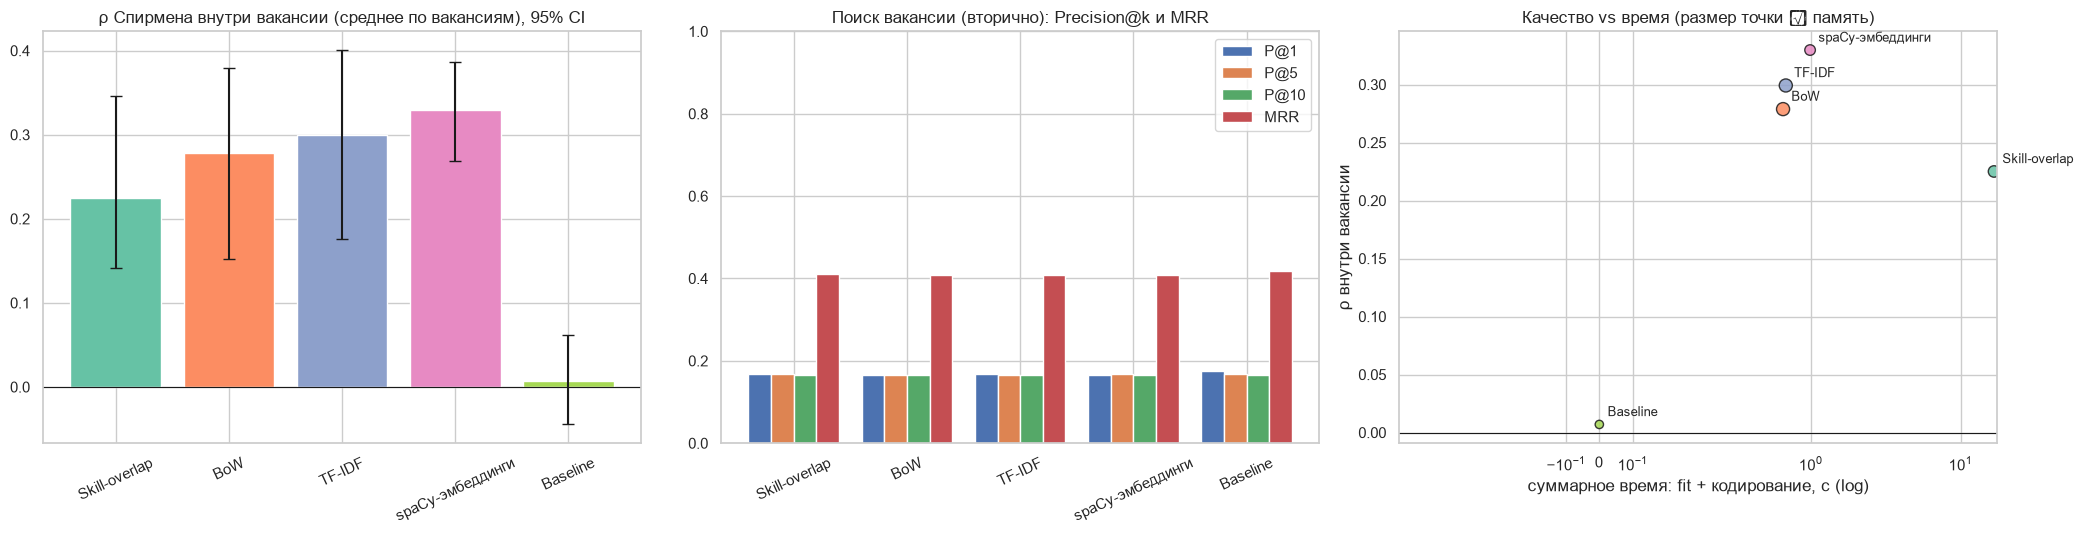

In [28]:
names = list(results)
short = [n.split(" (")[0] for n in names]
colors = sns.color_palette("Set2", len(names))
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))

rho = np.array([results[n]["rank"]["rho"] for n in names], dtype=float)
lo = np.array([results[n]["rank"]["rho_ci"][0] for n in names], dtype=float); hi = np.array([results[n]["rank"]["rho_ci"][1] for n in names], dtype=float)
axes[0].bar(short, rho, yerr=np.clip(np.vstack([rho - lo, hi - rho]), 0, None), capsize=4, color=colors)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_title("ρ Спирмена внутри вакансии (среднее по вакансиям), 95% CI"); axes[0].tick_params(axis="x", rotation=25)

w = 0.2
for j, mtr in enumerate(["P@1", "P@5", "P@10", "MRR"]):
    axes[1].bar(np.arange(len(names)) + j * w, [results[n][mtr] for n in names], w, label=mtr)
axes[1].set_xticks(np.arange(len(names)) + 1.5 * w); axes[1].set_xticklabels(short, rotation=25); axes[1].set_ylim(0, 1)
axes[1].set_title("Поиск вакансии (вторично): Precision@k и MRR"); axes[1].legend()

tot_t = [results[n]["fit_s"] + results[n]["encode_s"] for n in names]
mem = [max(results[n]["peak_py_mb"] or 0, results[n]["d_rss_mb"] or 0, 1) for n in names]
axes[2].scatter(tot_t, rho, s=[30 + 6 * m for m in mem], c=colors, edgecolor="k", alpha=0.85)
for x, y, s in zip(tot_t, rho, short):
    axes[2].annotate(s, (x, y), textcoords="offset points", xytext=(6, 6), fontsize=9)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_xscale("symlog", linthresh=0.5); axes[2].set_xlabel("суммарное время: fit + кодирование, с (log)"); axes[2].set_ylabel("ρ внутри вакансии")
axes[2].set_title("Качество vs время (размер точки ∝ память)")
plt.tight_layout(); plt.show()

In [29]:
# ρ внутри вакансии для всех представлений и для итогового балла продукта; для справки — «общая» ρ по всем парам (она смешивает вакансии)
tf_name = next(n for n in results if "TF-IDF" in n); sk_name = next(n for n in results if "Skill-overlap" in n)
final_own = 0.6 * results[sk_name]["own_sim"] + 0.4 * results[tf_name]["own_sim"]       # формула продукта
PRODUCT = "Итоговый балл продукта (0.6·overlap + 0.4·TF-IDF)"
rank_inputs = {n.split(" (")[0]: r["own_sim"] for n, r in results.items()}
rank_inputs[PRODUCT] = final_own

ok = ~np.isnan(ms_te)
rank_rows = {}
for n, sim in rank_inputs.items():
    k = rank_summary(within_vacancy_ranking(sim, ms_te, own_idx))
    rank_rows[n] = {"вакансий": k["n_vac"], "ρ внутри вакансии": k["rho"], "95% CI": fmt_ci(k["rho_ci"]),
                    "P@10 (топ-20%)": k["p10"], "P@10 случайно": k["base"],
                    "ρ по всем парам (смешивает вакансии)": spearmanr(sim[ok], ms_te[ok]).statistic}
    if n == PRODUCT:
        product_rank = k
rank_tbl = pd.DataFrame(rank_rows).T
rank_disp = rank_tbl.astype({c: float for c in rank_tbl.columns if c not in ("95% CI",)}).round(3)
rank_disp["вакансий"] = rank_disp["вакансий"].astype(int)
display(rank_disp)
print(f"(n = {ok.sum()} пар «резюме — своя вакансия» из test; matched_score — оценка из самого датасета, её природа неизвестна. "
      "«ρ по всем парам» оставлена только для сравнения: она смешивает разные вакансии и поэтому не используется как метрика качества.)")

_cand = {n: r for n, r in results.items() if not n.startswith("Baseline") and r["rank"]["n_vac"] > 0}
best_name = max(_cand, key=lambda n: _cand[n]["rank"]["rho"]) if _cand else tf_name        # лучшее представление по ρ внутри вакансии
print(f"Лучшее представление по ρ внутри вакансии: «{best_name}»")

,вакансий,ρ внутри вакансии,95% CI,P@10 (топ-20%),P@10 случайно,ρ по всем парам (смешивает вакансии)
Skill-overlap,6,0.225,[+0.142; +0.346],0.517,0.289,0.292
BoW,6,0.279,[+0.153; +0.380],0.533,0.289,0.274
TF-IDF,6,0.299,[+0.176; +0.401],0.650,0.289,0.291
spaCy-эмбеддинги,6,0.330,[+0.269; +0.386],0.650,0.289,0.148
Baseline,6,0.007,[-0.045; +0.062],0.233,0.289,0.017
Итоговый балл продукта (0.6·overlap + 0.4·TF-IDF),6,0.306,[+0.177; +0.424],0.567,0.289,0.318


(n = 2033 пар «резюме — своя вакансия» из test; matched_score — оценка из самого датасета, её природа неизвестна. «ρ по всем парам» оставлена только для сравнения: она смешивает разные вакансии и поэтому не используется как метрика качества.)
Лучшее представление по ρ внутри вакансии: «spaCy-эмбеддинги (en_core_web_md, mean)»


In [30]:
# автоматические выводы
cls = {n: r for n, r in results.items() if not n.startswith("Baseline")}
base = results[BASE_NAME]
valid = {n: r for n, r in cls.items() if r["rank"]["n_vac"] > 0}
print("ВЫВОДЫ по сравнению представлений (посчитаны в этом запуске):")
if valid:
    kb = results[best_name]["rank"]
    print(f"• Согласие с matched_score внутри вакансии: лучшее — «{best_name}»: ρ = {kb['rho']:+.3f} "
          f"(95% CI [{kb['rho_ci'][0]:+.3f}; {kb['rho_ci'][1]:+.3f}], вакансий {kb['n_vac']}), P@10 = {kb['p10']:.3f} при случайном уровне {kb['base']:.3f}; "
          f"случайный порядок: ρ = {base['rank']['rho']:+.3f}.")
    ties = [n for n in valid if n != best_name and kb["rho_ci"][0] <= valid[n]["rank"]["rho"] <= kb["rho_ci"][1]]
    print("  Статистически неотличимы от лучшего (ρ внутри его 95% CI): " + (", ".join(t.split(" (")[0] for t in ties) if ties else "нет — лидер отрывается"))
    if kb["rho_ci"][0] <= 0 <= kb["rho_ci"][1]:
        print("  ⚠ Доверительный интервал лучшего представления включает 0: у этих представлений нет подтверждённой связи сходства с matched_score внутри вакансии. "
              "Выбор «лучшего» ненадёжен.")
    elif kb["rho"] < 0.1:
        print("  ⚠ Связь с matched_score статистически отличима от нуля, но очень слабая (ρ < 0.1).")
else:
    print(f"• ⚠ Нет вакансий с ≥ {MIN_CANDS_PER_VACANCY} кандидатами в test — ρ внутри вакансии посчитать нельзя (см. MIN_CANDS_PER_VACANCY / SPLIT_FRACTIONS).")
best_mrr = max(cls, key=lambda n: cls[n]["MRR"])
print(f"• Поиск вакансии (вторично): лучший MRR — «{best_mrr}» (MRR {cls[best_mrr]['MRR']:.3f}, P@5 {cls[best_mrr]['P@5']:.3f}); "
      f"случайный порядок: MRR {base['MRR']:.3f}, P@5 {base['P@5']:.3f}. Высокие значения здесь означают «резюме легко отнести к его вакансии», а не «matching качественный» (см. 10b).")
fast = min(cls, key=lambda n: cls[n]["fit_s"] + cls[n]["encode_s"])
print(f"• Быстрее всего (fit+кодирование): «{fast}» — {cls[fast]['fit_s'] + cls[fast]['encode_s']:.1f} с.")
print(f"• Память (пик Python / модель): " + "; ".join(f"{n.split(' (')[0]}: {(r['peak_py_mb'] or 0):.0f}/{r['model_mb']:.1f} MB" for n, r in cls.items()))

ВЫВОДЫ по сравнению представлений (посчитаны в этом запуске):
• Согласие с matched_score внутри вакансии: лучшее — «spaCy-эмбеддинги (en_core_web_md, mean)»: ρ = +0.330 (95% CI [+0.269; +0.386], вакансий 6), P@10 = 0.650 при случайном уровне 0.289; случайный порядок: ρ = +0.007.
  Статистически неотличимы от лучшего (ρ внутри его 95% CI): BoW, TF-IDF
• Поиск вакансии (вторично): лучший MRR — «Skill-overlap (NER → бинарные навыки)» (MRR 0.410, P@5 0.168); случайный порядок: MRR 0.417, P@5 0.168. Высокие значения здесь означают «резюме легко отнести к его вакансии», а не «matching качественный» (см. 10b).
• Быстрее всего (fit+кодирование): «BoW (counts, 1–2-граммы)» — 0.7 с.
• Память (пик Python / модель): Skill-overlap: 6/0.1 MB; BoW: 10/0.3 MB; TF-IDF: 10/0.4 MB; spaCy-эмбеддинги: 5/22.9 MB


## 10b. Диагностика: откуда брались ≈100% и что изменилось
Раньше классификатор «резюме → название вакансии» давал Accuracy ≈ 1.0 у **всех** представлений, включая самые примитивные (бинарные навыки, мешок слов). Это сигнал не о силе моделей, а о том, что **задача тривиальна или есть утечка**: при разбиении по строкам резюме одной вакансии попадали и в `train`, и в `test`, а внутри вакансии резюме устроены «семейством» (общий шаблон текста / навыков).

Что проверяется ниже:
* **A.** разбиение теперь идёт по вакансиям: ни одна вакансия не встречается в двух частях;
* **B.** *воспроизведение проблемы* — только как диагностика, на «неправильном» разбиении по строкам: какое поле резюме по отдельности восстанавливает название вакансии (и осталось ли оно во входе `RESUME_FIELDS`);
* **C.** остались ли почти-дубликаты резюме между `train` и `test` при разбиении по вакансиям;
* **D.** упоминается ли название вакансии прямо в тексте резюме.

Дальше (абляция) — как меняются метрики в зависимости от входных полей.

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

# ── A. Контроль разбиения ──
print("A. Разбиение по вакансиям (GROUP_COL = %r):" % GROUP_COL)
for s in ("vocab", "train", "test"):
    sub = df[df["split"] == s]
    print(f"   {s:<5}: {len(sub):>5} резюме, {sub['vacancy_id'].nunique():>4} вакансий")
print(f"   общих вакансий между частями: {len(_vac['train'] & _vac['test']) + len(_vac['vocab'] & _vac['train']) + len(_vac['vocab'] & _vac['test'])} "
      f"(проверено assert-ом в разделе 4); общих названий train∩test: {len(_titles['train'] & _titles['test'])}")

# ── B. Воспроизведение проблемы: «неправильное» разбиение по строкам (ТОЛЬКО диагностика, в метриках не участвует) ──
_vc = df["label"].value_counts()
_diag_classes = [c for c, n in _vc.items() if c and n >= 20][:30]
field_acc = {}
print("\nB. Диагностика на разбиении ПО СТРОКАМ (так было раньше): какое поле выдаёт название вакансии?")
if len(_diag_classes) >= 3:
    dd = df[df["label"].isin(_diag_classes)]
    d_tr, d_te = train_test_split(dd, test_size=0.2, stratify=dd["label"], random_state=SEED)
    maj = d_te["label"].value_counts(normalize=True).iloc[0]
    cur_key = "ТЕКУЩИЙ ВХОД (" + " + ".join(RESUME_FIELDS) + ")"
    old_key = "прежний вход (цель + навыки + обязанности)"
    diag_fields = {f: [f] for f in ALL_RESUME_FIELDS}
    diag_fields[cur_key] = list(RESUME_FIELDS)
    diag_fields[old_key] = ["career_objective", "skills", "responsibilities"]
    for name, flds in diag_fields.items():
        try:
            a, b = build_resume_text(d_tr, flds), build_resume_text(d_te, flds)
            vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=10000).fit(a)
            clf = LinearSVC(C=1.0, random_state=SEED).fit(vec.transform(a), d_tr["label"])
            field_acc[name] = float((clf.predict(vec.transform(b)) == d_te["label"].to_numpy()).mean())
        except ValueError:                                  # поле почти всегда пустое → пустой словарь
            field_acc[name] = float("nan")
    display(pd.Series(field_acc, name="Accuracy (разбиение по строкам)").to_frame().round(3))
    print(f"   {len(_diag_classes)} названий, {len(dd)} резюме; мажоритарный baseline: {maj:.3f}")
    leaky = [f for f in ALL_RESUME_FIELDS if field_acc.get(f, 0) >= 0.9]
    print(f"   Поля, которые по отдельности восстанавливают название при разбиении по строкам (Accuracy ≥ 0.9): {leaky or 'нет'}")
    print(f"   Из них оставлены во входе RESUME_FIELDS: {[f for f in leaky if f in RESUME_FIELDS] or 'нет'}")
    print(f"   Прежний вход: Accuracy {field_acc[old_key]:.3f}; текущий вход: Accuracy {field_acc[cur_key]:.3f}")
    if field_acc[cur_key] >= 0.9:
        print("   ⚠ Даже сокращённый вход при разбиении по строкам почти однозначно выдаёт вакансию → классификация по названию остаётся тривиальной; "
              "поэтому она не используется как метрика качества.")
else:
    print(f"   (пропущено: названий с ≥ 20 резюме меньше трёх — {len(_diag_classes)})")

# ── C. Почти-дубликаты между train и test при разбиении по вакансиям ──
def _nn_max(Xa, Xb, chunk=500):
    out = np.empty(Xa.shape[0])
    for i in range(0, Xa.shape[0], chunk):
        out[i:i + chunk] = cosine_similarity(Xa[i:i + chunk], Xb).max(1)
    return out
_nn = _nn_max(_tf.encode(te_texts), _tf.encode(tr_texts))
print(f"\nC. Ближайший train-сосед каждого test-резюме (TF-IDF cosine, разбиение по вакансиям): медиана {np.median(_nn):.3f}; "
      f"доля с cos ≥ 0.90: {(_nn >= 0.90).mean():.0%}; ≥ 0.99: {(_nn >= 0.99).mean():.0%}")
_trset = set(tr_texts)
print(f"   test-резюме, чей входной текст дословно встречается в train (у другой вакансии): {np.mean([t in _trset for t in te_texts]):.1%}")

# ── D. Название вакансии прямо в тексте резюме ──
_lab = te["label"].to_numpy(dtype=object)
_has = np.array([bool(l) for l in _lab])
print(f"\nD. Доля test-резюме, в тексте которых дословно есть название вакансии: "
      f"текущий вход {np.mean([l in t.lower() for l, t, h in zip(_lab, te['resume_text'], _has) if h]):.1%}; "
      f"все четыре поля {np.mean([l in t.lower() for l, t, h in zip(_lab, te['resume_text_full'], _has) if h]):.1%}")

A. Разбиение по вакансиям (GROUP_COL = 'job_text'):
   vocab:  3727 резюме,   11 вакансий
   train:  3728 резюме,   11 вакансий
   test :  2033 резюме,    6 вакансий
   общих вакансий между частями: 0 (проверено assert-ом в разделе 4); общих названий train∩test: 0

B. Диагностика на разбиении ПО СТРОКАМ (так было раньше): какое поле выдаёт название вакансии?


,Accuracy (разбиение по строкам)
career_objective,0.013
skills,0.000
responsibilities,1.000
related_skils_in_job,0.002
ТЕКУЩИЙ ВХОД (career_objective + skills),0.000
прежний вход (цель + навыки + обязанности),1.000


   28 названий, 9488 резюме; мажоритарный baseline: 0.036
   Поля, которые по отдельности восстанавливают название при разбиении по строкам (Accuracy ≥ 0.9): ['responsibilities']
   Из них оставлены во входе RESUME_FIELDS: нет
   Прежний вход: Accuracy 1.000; текущий вход: Accuracy 0.000

C. Ближайший train-сосед каждого test-резюме (TF-IDF cosine, разбиение по вакансиям): медиана 1.000; доля с cos ≥ 0.90: 100%; ≥ 0.99: 100%
   test-резюме, чей входной текст дословно встречается в train (у другой вакансии): 100.0%

D. Доля test-резюме, в тексте которых дословно есть название вакансии: текущий вход 0.1%; все четыре поля 0.1%


### Абляция входных полей: что даёт каждое поле резюме
Для каждого набора полей строим TF-IDF (fit на `train`) и считаем на **разбиении по вакансиям** (а) ρ внутри вакансии с `matched_score` — главная метрика; (б) «поиск вакансии» P@1 и MRR — насколько легко по этому набору полей угадать, для какой вакансии написано резюме. Если P@1 близок к 1, а ρ при этом не растёт, поле добавляет «узнаваемость вакансии», но не информацию о соответствии. Случайный уровень P@1 при поиске = 1 / (число вакансий в test).

In [32]:
FIELD_SETS = {
    "только career_objective": ["career_objective"],
    "только skills": ["skills"],
    "только responsibilities": ["responsibilities"],
    "только related_skils_in_job": ["related_skils_in_job"],
    "ТЕКУЩИЙ ВХОД: " + " + ".join(RESUME_FIELDS): list(RESUME_FIELDS),
    "прежний вход: цель + навыки + обязанности": ["career_objective", "skills", "responsibilities"],
    "все четыре поля": list(ALL_RESUME_FIELDS),
}
abl_rows = []
for name, flds in FIELD_SETS.items():
    row = {"набор полей": name}
    try:
        tr_t, te_t = build_resume_text(tr, flds).tolist(), build_resume_text(te, flds).tolist()
        vec = TfidfVectorizer(**TFIDF_PARAMS).fit(tr_t)
        S = cosine_similarity(vec.transform(te_t), vec.transform(pool_texts))
        own = S[np.arange(len(te)), own_idx]
        k, ret = rank_summary(within_vacancy_ranking(own, ms_te, own_idx)), retrieval_metrics(S, REL)
        row.update({"вакансий": k["n_vac"], "ρ внутри вакансии": k["rho"], "ρ 95% CI": fmt_ci(k["rho_ci"]),
                    "P@10 (топ-20%)": k["p10"], "поиск вакансии P@1": ret["P@1"], "MRR": ret["MRR"]})
    except ValueError:                                      # пустой словарь (поле почти всегда пустое)
        row.update({"вакансий": 0, "ρ внутри вакансии": float("nan"), "ρ 95% CI": "—", "P@10 (топ-20%)": float("nan"),
                    "поиск вакансии P@1": float("nan"), "MRR": float("nan")})
    abl_rows.append(row)
abl = pd.DataFrame(abl_rows).set_index("набор полей")
display(abl.round(3))
print(f"Случайный уровень: ρ ≈ 0, P@10 ≈ {TOP_FRAC:.2f}, P@1 при поиске ≈ {1 / len(pool):.3f}")

cur = next(i for i in abl.index if i.startswith("ТЕКУЩИЙ")); old = next(i for i in abl.index if i.startswith("прежний")); allf = "все четыре поля"
p1, rho_a = abl["поиск вакансии P@1"].astype(float), abl["ρ внутри вакансии"].astype(float)
if p1.notna().any():
    top1 = p1.idxmax()
    print(f"• Легче всего угадать вакансию по набору «{top1}» (P@1 = {p1[top1]:.3f}); текущий вход: P@1 = {p1[cur]:.3f}, прежний: {p1[old]:.3f}.")
print(f"• ρ внутри вакансии: текущий вход {rho_a[cur]:+.3f}, прежний {rho_a[old]:+.3f}, все четыре поля {rho_a[allf]:+.3f}.")
if p1[cur] >= 0.9:
    print("⚠ Даже текущий вход почти однозначно определяет вакансию: метрики «поиска вакансии» нельзя читать как качество matching.")
if rho_a.notna().any() and abl.loc[rho_a.idxmax(), "ρ 95% CI"] != "—":
    lo_, hi_ = [float(x) for x in abl.loc[rho_a.idxmax(), "ρ 95% CI"].strip("[]").split(";")]
    if lo_ <= 0 <= hi_:
        print("⚠ Ни один набор полей не даёт ρ, отличимого от нуля: сходство текста с вакансией не воспроизводит matched_score (или matched_score определяется не текстом).")

,вакансий,ρ внутри вакансии,ρ 95% CI,P@10 (топ-20%),поиск вакансии P@1,MRR
набор полей,,,,,,
только career_objective,6,0.137,[+0.039; +0.220],0.567,0.167,0.408
только skills,6,0.287,[+0.148; +0.406],0.517,0.166,0.408
только responsibilities,0,NaN,—,NaN,1.000,1.000
только related_skils_in_job,6,0.187,[+0.097; +0.269],0.533,0.167,0.409
ТЕКУЩИЙ ВХОД: career_objective + skills,6,0.299,[+0.176; +0.401],0.650,0.167,0.408
прежний вход: цель + навыки + обязанности,6,-0.123,[-0.273; +0.024],0.233,0.999,1.000
все четыре поля,6,-0.161,[-0.341; +0.022],0.100,1.000,1.000


Случайный уровень: ρ ≈ 0, P@10 ≈ 0.20, P@1 при поиске ≈ 0.167
• Легче всего угадать вакансию по набору «только responsibilities» (P@1 = 1.000); текущий вход: P@1 = 0.167, прежний: 0.999.
• ρ внутри вакансии: текущий вход +0.299, прежний -0.123, все четыре поля -0.161.


## 11. Разбор ранжирования внутри вакансий (вместо матрицы ошибок)
Матрица ошибок и Accuracy относились к классификации «резюме → название вакансии». При разбиении по вакансиям эта задача не определена (названия теста не встречаются в `train`), а при разбиении по строкам — тривиальна (раздел 10b), поэтому матрица ошибок убрана.

Вместо неё разбираем ранжирование **лучшей по ρ модели** на `test`: распределение ρ по вакансиям, «слабые» и «сильные» вакансии, средняя ошибка ранга кандидата (разность процентилей по сходству и по `matched_score` внутри вакансии; при случайном порядке ≈ 0.33, при идеальном 0), зависимость от длины резюме и числа найденных навыков, кандидаты с наибольшим расхождением.

Модель для разбора: «spaCy-эмбеддинги (en_core_web_md, mean)» | вакансий в оценке: 6 из 6 | ρ = +0.330, P@10 = 0.650


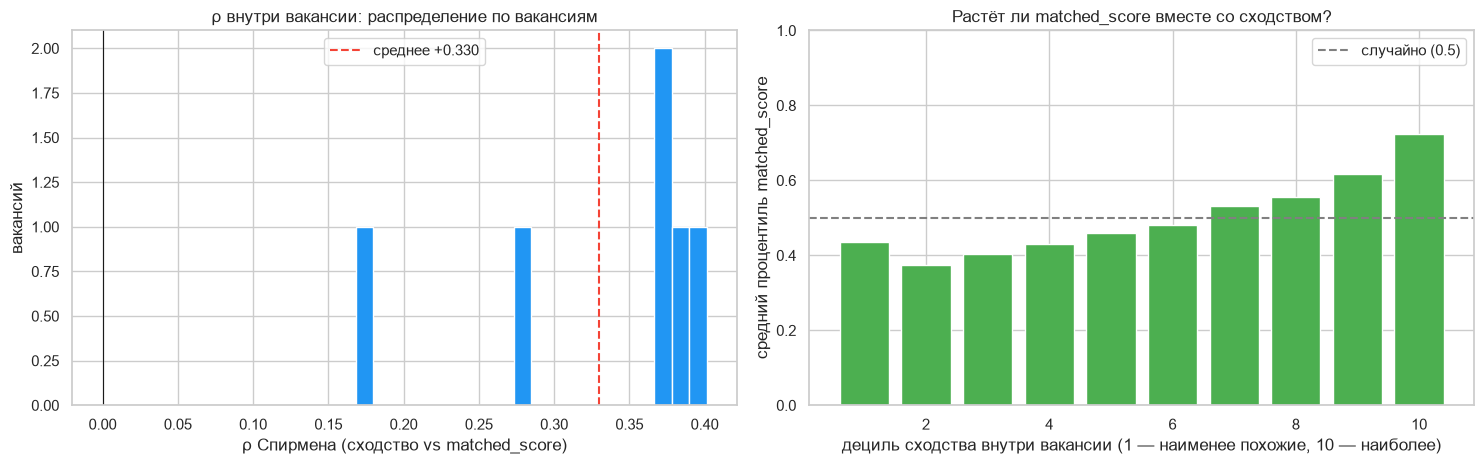

In [33]:
R = results[best_name]
own_best = R["own_sim"]
vac_tbl = within_vacancy_ranking(own_best, ms_te, own_idx)
vac_title = pd.Series(y_te).groupby(own_idx).first()                      # название вакансии по её номеру
vac_tbl["title"] = vac_tbl["vacancy"].map(vac_title)
HAVE_VAC = len(vac_tbl) > 0
print(f"Модель для разбора: «{best_name}» | вакансий в оценке: {len(vac_tbl)} из {len(pool)} | ρ = {R['rank']['rho']:+.3f}, P@10 = {R['rank']['p10']:.3f}")

if not HAVE_VAC:
    print(f"⚠ Нет вакансий с ≥ {MIN_CANDS_PER_VACANCY} кандидатами с matched_score — разбор ранжирования пропущен (см. MIN_CANDS_PER_VACANCY / SPLIT_FRACTIONS).")
else:
    # процентильные ранги внутри вакансии: по сходству и по matched_score
    ev = pd.DataFrame({"vac": own_idx, "sim": own_best, "ms": ms_te})
    ev["ok"] = ev["vac"].isin(set(vac_tbl["vacancy"])) & ev["ms"].notna()
    ev["pct_sim"] = np.nan; ev["pct_ms"] = np.nan
    _g = ev[ev["ok"]].groupby("vac")
    ev.loc[ev["ok"], "pct_sim"] = _g["sim"].rank(pct=True)
    ev.loc[ev["ok"], "pct_ms"] = _g["ms"].rank(pct=True)
    ev["rank_err"] = (ev["pct_sim"] - ev["pct_ms"]).abs()

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    axes[0].hist(vac_tbl["rho"], bins=20, color="#2196F3", edgecolor="white")
    axes[0].axvline(0, color="k", lw=0.8)
    axes[0].axvline(vac_tbl["rho"].mean(), color="#F44336", ls="--", label=f"среднее {vac_tbl['rho'].mean():+.3f}")
    axes[0].set_title("ρ внутри вакансии: распределение по вакансиям"); axes[0].set_xlabel("ρ Спирмена (сходство vs matched_score)"); axes[0].set_ylabel("вакансий"); axes[0].legend()

    e = ev[ev["ok"]]
    dec = e.groupby(pd.cut(e["pct_sim"], np.linspace(0, 1, 11), include_lowest=True), observed=False)["pct_ms"].mean()
    axes[1].bar(range(1, len(dec) + 1), dec.values, color="#4CAF50")
    axes[1].axhline(0.5, color="gray", ls="--", label="случайно (0.5)")
    axes[1].set_xlabel("дециль сходства внутри вакансии (1 — наименее похожие, 10 — наиболее)"); axes[1].set_ylabel("средний процентиль matched_score")
    axes[1].set_title("Растёт ли matched_score вместе со сходством?"); axes[1].set_ylim(0, 1); axes[1].legend()
    plt.tight_layout(); plt.show()

In [34]:
if HAVE_VAC:
    _cols = {"title": "название", "n": "кандидатов", "rho": "ρ", "p_at_k": "P@10", "base": "P@10 случайно"}
    print("Вакансии с самым слабым согласием (ρ ниже всех):")
    display(vac_tbl.sort_values("rho").head(8)[list(_cols)].rename(columns=_cols).round(3))
    print("С самым сильным согласием:")
    display(vac_tbl.sort_values("rho", ascending=False).head(5)[list(_cols)].rename(columns=_cols).round(3))
    share_pos, share_neg = float((vac_tbl["rho"] > 0).mean()), float((vac_tbl["rho"] < 0).mean())
    print(f"Вакансий с ρ > 0: {share_pos:.0%}; с ρ < 0: {share_neg:.0%}")
    if len(vac_tbl) > 3 and vac_tbl["n"].nunique() > 1:
        rr = spearmanr(vac_tbl["n"], vac_tbl["rho"])
        print(f"Связь числа кандидатов на вакансию и ρ: Spearman ρ = {rr.statistic:.2f} (p = {rr.pvalue:.3f})")

Вакансии с самым слабым согласием (ρ ниже всех):


,название,кандидатов,ρ,P@10,P@10 случайно
0,senior software engineer,339,0.168,0.3,0.206
1,machine learning (ml) engineer,338,0.285,0.8,0.482
5,civil engineer,340,0.367,0.9,0.209
4,"full stack developer (python,react js)",338,0.373,0.8,0.432
2,asst. manager/ manger (administrative),339,0.383,0.4,0.204
3,sr.officer / executive - internal audit,339,0.401,0.7,0.201


С самым сильным согласием:


,название,кандидатов,ρ,P@10,P@10 случайно
3,sr.officer / executive - internal audit,339,0.401,0.7,0.201
2,asst. manager/ manger (administrative),339,0.383,0.4,0.204
4,"full stack developer (python,react js)",338,0.373,0.8,0.432
5,civil engineer,340,0.367,0.9,0.209
1,machine learning (ml) engineer,338,0.285,0.8,0.482


Вакансий с ρ > 0: 100%; с ρ < 0: 0%
Связь числа кандидатов на вакансию и ρ: Spearman ρ = 0.09 (p = 0.862)


In [35]:
if HAVE_VAC:
    # ошибка ранга vs длина резюме и число найденных навыков (NER)
    te_skill_counts = np.array([len(s) for s in predict_skills(nlp_eval, te_texts)])
    def err_by_quartile(values, name):
        v = pd.Series(np.asarray(values, dtype=float), index=ev.index)
        m = ev["ok"]
        q = pd.qcut(v[m].rank(method="first"), 4, labels=["Q1 (мин.)", "Q2", "Q3", "Q4 (макс.)"])
        g = pd.DataFrame({"q": q, "err": ev.loc[m, "rank_err"]}).groupby("q", observed=True).agg(ошибка_ранга=("err", "mean"), n=("err", "size"))
        g["диапазон"] = [f"{v[m][q == k].min():.0f}–{v[m][q == k].max():.0f}" for k in g.index]
        g.index.name = name; return g
    if int(ev["ok"].sum()) >= 8:
        by_len, by_sk = err_by_quartile(te["n_words"].to_numpy(), "длина резюме (слов)"), err_by_quartile(te_skill_counts, "найдено навыков")
        display(by_len.round(3)); display(by_sk.round(3))
    else:
        by_len = by_sk = None
        print("Слишком мало кандидатов для квартилей.")
    print(f"Средняя ошибка ранга: {ev.loc[ev['ok'], 'rank_err'].mean():.3f} (случайный порядок ≈ 0.333, идеальный 0)")

,ошибка_ранга,n,диапазон
длина резюме (слов),,,
Q1 (мин.),0.275,509,7–26
Q2,0.254,508,26–47
Q3,0.256,508,47–66
Q4 (макс.),0.249,508,66–372


,ошибка_ранга,n,диапазон
найдено навыков,,,
Q1 (мин.),0.280,509,3–11
Q2,0.247,508,11–16
Q3,0.254,508,16–31
Q4 (макс.),0.254,508,31–145


Средняя ошибка ранга: 0.259 (случайный порядок ≈ 0.333, идеальный 0)


In [36]:
if HAVE_VAC:
    ev["gap"] = ev["pct_sim"] - ev["pct_ms"]
    te_skills_sets = predict_skills(nlp_eval, te_texts)
    def _show(title, idxs):
        print(title)
        for i in idxs:
            print(f"— вакансия: «{vac_title[own_idx[i]]}» | процентиль по сходству {ev.at[i, 'pct_sim']:.2f}, по matched_score {ev.at[i, 'pct_ms']:.2f} (matched_score = {ms_te[i]:.2f})")
            print(f"  навыки (NER): {sorted(te_skills_sets[i])[:8]}")
            print(f"  текст: {te_texts[i][:220]}…\n")
    _ok = ev[ev["ok"]]
    _show("СХОДСТВО ВЫСОКОЕ, matched_score НИЗКИЙ (наибольшее расхождение):", _ok.sort_values("gap", ascending=False).head(3).index)
    _show("СХОДСТВО НИЗКОЕ, matched_score ВЫСОКИЙ (наибольшее расхождение):", _ok.sort_values("gap").head(3).index)

СХОДСТВО ВЫСОКОЕ, matched_score НИЗКИЙ (наибольшее расхождение):
— вакансия: «senior software engineer» | процентиль по сходству 0.95, по matched_score 0.02 (matched_score = 0.28)
  навыки (NER): ['automotive', 'basic', 'broadcast', 'ca', 'cable', 'cables', 'cabling', 'carpentry']
  текст: automotive, basic, broadcast, cables, cable, cabling, carpentry, chill, CA, conversion, Council, SC, Direction, documentation, electrical systems, electronics, equipment installation, experimentation, FAX, forms, governm…

— вакансия: «sr.officer / executive - internal audit» | процентиль по сходству 0.96, по matched_score 0.06 (matched_score = 0.42)
  навыки (NER): ['apple', 'automation', 'banking', 'budgets', 'business plan', 'camera', 'client', 'closing']
  текст: Net, photo, agile, analyst, Apple, automation, banking, budgets, business plan, closing, com, consulting, content, contracts, credit, encryption, client, customer satisfaction, data migration, database administration, dr…

— вакансия: «f

In [37]:
if HAVE_VAC:
    print("ИНТЕРПРЕТАЦИЯ (числа из этого запуска):")
    _err = float(ev.loc[ev["ok"], "rank_err"].mean())
    print(f"• Средняя ошибка ранга {_err:.3f} при случайном порядке ≈ 0.333: " + ("заметно лучше случайного." if _err < 0.30 else "почти как при случайном порядке."))
    print(f"• ρ > 0 у {share_pos:.0%} вакансий, ρ < 0 у {share_neg:.0%}: " + ("согласие в целом одного знака." if share_pos >= 0.7 else "согласие нестабильно от вакансии к вакансии."))
    if by_len is not None:
        print("• Ошибка ранга по квартилям длины резюме: " + ", ".join(f"{k}: {v:.2f}" for k, v in by_len["ошибка_ранга"].items())
              + " — " + ("короткие резюме ранжируются хуже." if by_len["ошибка_ранга"].iloc[0] > by_len["ошибка_ранга"].iloc[-1] + 0.03 else "явной зависимости от длины нет."))
        print("• Ошибка ранга по квартилям числа найденных навыков: " + ", ".join(f"{k}: {v:.2f}" for k, v in by_sk["ошибка_ранга"].items()) + ".")
    print("• Природа matched_score неизвестна: если ρ ≈ 0, это значит, что текстовое сходство не воспроизводит эту оценку, а не обязательно что модели «плохие».")
    print("• Что делать дальше: обучить ранжирующую модель (learning-to-rank) на train с matched_score как целью; добавить признаки опыта/образования; "
          "проверить на отдельных вакансиях, где ρ отрицательна (таблица выше), не завышены ли там требования или нет ли шума в matched_score.")

ИНТЕРПРЕТАЦИЯ (числа из этого запуска):
• Средняя ошибка ранга 0.259 при случайном порядке ≈ 0.333: заметно лучше случайного.
• ρ > 0 у 100% вакансий, ρ < 0 у 0%: согласие в целом одного знака.
• Ошибка ранга по квартилям длины резюме: Q1 (мин.): 0.28, Q2: 0.25, Q3: 0.26, Q4 (макс.): 0.25 — явной зависимости от длины нет.
• Ошибка ранга по квартилям числа найденных навыков: Q1 (мин.): 0.28, Q2: 0.25, Q3: 0.25, Q4 (макс.): 0.25.
• Природа matched_score неизвестна: если ρ ≈ 0, это значит, что текстовое сходство не воспроизводит эту оценку, а не обязательно что модели «плохие».
• Что делать дальше: обучить ранжирующую модель (learning-to-rank) на train с matched_score как целью; добавить признаки опыта/образования; проверить на отдельных вакансиях, где ρ отрицательна (таблица выше), не завышены ли там требования или нет ли шума в matched_score.


## 12. Продуктовая модель NER и демонстрация
Продуктовая модель — `en_core_web_md` (без встроенного NER) + EntityRuler **с тем же словарём, для которого посчитаны метрики** (`vocab`-часть + кураторский список). Токенизатор у `spacy.blank("en")` и `en_core_web_md` один и тот же, поэтому результаты оценочной (blank) и продуктовой (md) моделей совпадают — это проверяется в конце.

In [38]:
from spacy import displacy

nlp, n_prod = build_ner(pattern_skills, base="md")
print(f"Продуктовый пайплайн готов. Паттернов: {n_prod}, из них мультитокенных: "
      f"{sum(1 for p in nlp.get_pipe('entity_ruler').patterns if len(p['pattern']) > 1)}")

def extract_skills(text, model=None):
    doc = (model or nlp)(clean_text(text))
    return doc, sorted({normalize_skill(ent.text) for ent in doc.ents if ent.label_ == "SKILL"})

test_text = ("I am a Senior Developer with expertise in Python, React, and PostgreSQL. "
             "I also have experience with AWS, Docker, machine learning, and deep learning. "
             "Familiar with CI/CD pipelines and Kubernetes.")
doc, extracted = extract_skills(test_text)
print("Найденные навыки:", extracted, f"(всего {len(extracted)})")
displacy.render(doc, style="ent", jupyter=True)

Продуктовый пайплайн готов. Паттернов: 3970, из них мультитокенных: 2763
Найденные навыки: ['aws', 'ci/cd', 'deep learning', 'developer', 'docker', 'kubernetes', 'machine learning', 'pipelines', 'postgresql', 'python', 'react'] (всего 11)


## 13. Prompt Engineering: генерация рекомендаций
Раньше вызов `get_groq_recommendations` был закомментирован, а `analyze_resume` его вызывал — на чистом запуске падал `NameError`. Теперь:
* если задан `GROQ_API_KEY` (переменная окружения или Kaggle Secret) и установлен пакет `groq` — рекомендации даёт LLM;
* иначе автоматически используется детерминированный rule-based вариант (тот же формат из 5 разделов), ноутбук выполняется целиком без ключей и интернета.

In [39]:
LEARNING_TIPS = {
    "kubernetes": "пройдите курс CKA и практикуйтесь на killer.sh", "mlflow": "изучите MLflow по официальной документации",
    "spark": "Databricks Academy — бесплатный курс по Spark", "airflow": "поднимите Airflow локально и напишите первые DAG",
    "terraform": "HashiCorp Learn — бесплатный курс Terraform", "golang": "tour.golang.org", "docker": "Play with Docker — бесплатная песочница",
    "aws": "AWS Free Tier + курс AWS Cloud Practitioner", "pytorch": "официальные туториалы на pytorch.org",
    "tensorflow": "TensorFlow Developer Certificate", "typescript": "документация typescriptlang.org", "postgresql": "postgresqltutorial.com",
}

def build_prompt(resume_text: str, job_description: str, analysis: dict) -> str:
    matched = ', '.join(analysis['matched']) if analysis['matched'] else 'нет совпадений'
    missing = ', '.join(analysis['missing']) if analysis['missing'] else 'все навыки присутствуют'
    return f"""You are an expert career coach and technical recruiter specializing in IT.
Analyze the following resume against a job description and provide actionable recommendations.

## Resume:
{resume_text.strip()}

## Job Description:
{job_description.strip()}

## Pre-computed Analysis:
- Skill match score: {analysis['score']:.0%}
- Matched skills: {matched}
- Missing required skills: {missing}

## Task:
Provide a structured response with:
1. **Overall Assessment** (2-3 sentences on the candidate's fit)
2. **Top 3 Strengths** (skills/experience that align well)
3. **Top 3 Gaps** (most critical missing skills or experience)
4. **Action Plan** (specific steps to improve match rate, e.g., courses, projects)
5. **Resume Optimization Tips** (2-3 concrete changes to the resume text)

Be specific, concise, and actionable. Focus on IT/tech context."""

def get_groq_recommendations(prompt: str, model: str = "llama-3.3-70b-versatile") -> str:
    key = os.environ.get("GROQ_API_KEY")
    if not key:
        try:
            from kaggle_secrets import UserSecretsClient
            key = UserSecretsClient().get_secret("GROQ_API_KEY")
        except Exception:
            pass
    if not key:
        raise RuntimeError("GROQ_API_KEY не задан")
    from groq import Groq
    resp = Groq(api_key=key).chat.completions.create(messages=[{"role": "user", "content": prompt}], model=model)
    return resp.choices[0].message.content

def rule_based_recommendations(overlap: dict, final: float) -> str:
    level = "отличное" if final >= 0.65 else "хорошее" if final >= 0.40 else "низкое"
    matched, missing = overlap["matched"], overlap["missing"]
    lines = ["## Overall Assessment",
             f"Итоговое соответствие — {level} ({final:.0%}); совпало {len(matched)} из {len(matched) + len(missing)} требуемых навыков.",
             "## Top 3 Strengths"] + [f"- {s}" for s in matched[:3]] + (["- (совпадений навыков нет)"] if not matched else [])
    lines += ["## Top 3 Gaps"] + [f"- {s}" for s in missing[:3]] + (["- (пробелов нет)"] if not missing else [])
    lines += ["## Action Plan"] + [f"- {s}: {LEARNING_TIPS.get(s, 'изучите по официальной документации и сделайте небольшой проект')}" for s in missing[:5]]
    lines += ["## Resume Optimization Tips",
              "- Добавьте измеримые результаты (например, «ускорил обработку на 40%»).",
              "- Вынесите раздел Technical Skills с явным списком технологий.",
              "- Используйте формулировки навыков из текста вакансии."]
    return "\n".join(lines)

def get_recommendations(prompt, overlap, final, use_llm="auto"):
    if use_llm in ("auto", True):
        try:
            return get_groq_recommendations(prompt), "groq"
        except Exception as exc:
            if use_llm is True:
                raise
            print(f"[LLM недоступен: {type(exc).__name__}: {str(exc)[:70]}] → используются rule-based рекомендации")
    return rule_based_recommendations(overlap, final), "rule-based"

## 14. Финальный пайплайн

In [40]:
def analyze_resume(resume_text: str, job_description: str, verbose: bool = True, use_llm="auto") -> dict:
    """1) очистка → 2) NER навыков резюме и вакансии → 3) skill overlap → 4) TF-IDF cosine (векторизатор из train) → 5) рекомендации."""
    resume_clean, job_clean = clean_text(resume_text), clean_text(job_description)
    _, resume_skills = extract_skills(resume_clean)
    _, job_skills = extract_skills(job_clean)
    overlap = skill_overlap_score(resume_skills, job_skills)
    tfidf = matcher.match(resume_clean, job_clean)
    final = round(0.6 * overlap['score'] + 0.4 * tfidf, 4)
    prompt = build_prompt(resume_text, job_description, overlap)
    recs, source = get_recommendations(prompt, overlap, final, use_llm)
    result = {"resume_skills": resume_skills, "job_skills": job_skills, "skill_overlap": overlap, "tfidf_similarity": tfidf,
              "final_score": final, "llm_prompt": prompt, "recommendations": recs, "recommendations_source": source}
    if verbose:
        print("=" * 60); print("         АНАЛИЗ СООТВЕТСТВИЯ РЕЗЮМЕ И ВАКАНСИИ"); print("=" * 60)
        print(f" Навыки кандидата   : {len(resume_skills)}: {', '.join(resume_skills[:10])}…")
        print(f" Требования вакансии: {len(job_skills)}: {', '.join(job_skills[:10])}…")
        print(f" Skill Overlap      : {overlap['score']:.1%}\n TF-IDF Similarity  : {tfidf:.4f}\n Итоговая оценка    : {final:.1%}")
        print(f" Совпали  : {', '.join(overlap['matched']) or 'нет'}\n Отсутствуют: {', '.join(overlap['missing']) or 'нет'}")
        print("=" * 60); print(f"Рекомендации (источник: {source}):\n{recs}")
    return result

SAMPLE_RESUME = """
Experienced Data Scientist with 4 years of industry experience.
Proficient in Python, pandas, scikit-learn, TensorFlow, and PyTorch.
Strong background in machine learning, deep learning, and NLP.
Worked with PostgreSQL, MongoDB, AWS S3, and Spark.
Familiar with Docker, Git, and CI/CD pipelines.
Experience building REST APIs with FastAPI and Flask.
"""
SAMPLE_JOB = """
We are looking for a Machine Learning Engineer to join our team.
Requirements:
- Python (3+ years)
- TensorFlow or PyTorch
- Experience with NLP and transformer models
- SQL databases (PostgreSQL preferred)
- Docker and Kubernetes
- AWS or GCP cloud platforms
- MLflow or similar experiment tracking
- Strong understanding of statistics and algorithms
"""
result = analyze_resume(SAMPLE_RESUME, SAMPLE_JOB)

[LLM недоступен: RuntimeError: GROQ_API_KEY не задан] → используются rule-based рекомендации
         АНАЛИЗ СООТВЕТСТВИЯ РЕЗЮМЕ И ВАКАНСИИ
 Навыки кандидата   : 20: aws, ci/cd, data scientist, deep learning, docker, fastapi, flask, git, machine learning, mongodb…
 Требования вакансии: 16: algorithms, aws, cloud, databases, docker, gcp, kubernetes, machine learning engineer, mlflow, natural language processing…
 Skill Overlap      : 43.8%
 TF-IDF Similarity  : 0.2177
 Итоговая оценка    : 35.0%
 Совпали  : aws, docker, natural language processing, postgresql, python, pytorch, tensorflow
 Отсутствуют: algorithms, cloud, databases, gcp, kubernetes, machine learning engineer, mlflow, sql, statistics
Рекомендации (источник: rule-based):
## Overall Assessment
Итоговое соответствие — низкое (35%); совпало 7 из 16 требуемых навыков.
## Top 3 Strengths
- aws
- docker
- natural language processing
## Top 3 Gaps
- algorithms
- cloud
- databases
## Action Plan
- algorithms: изучите по официальной

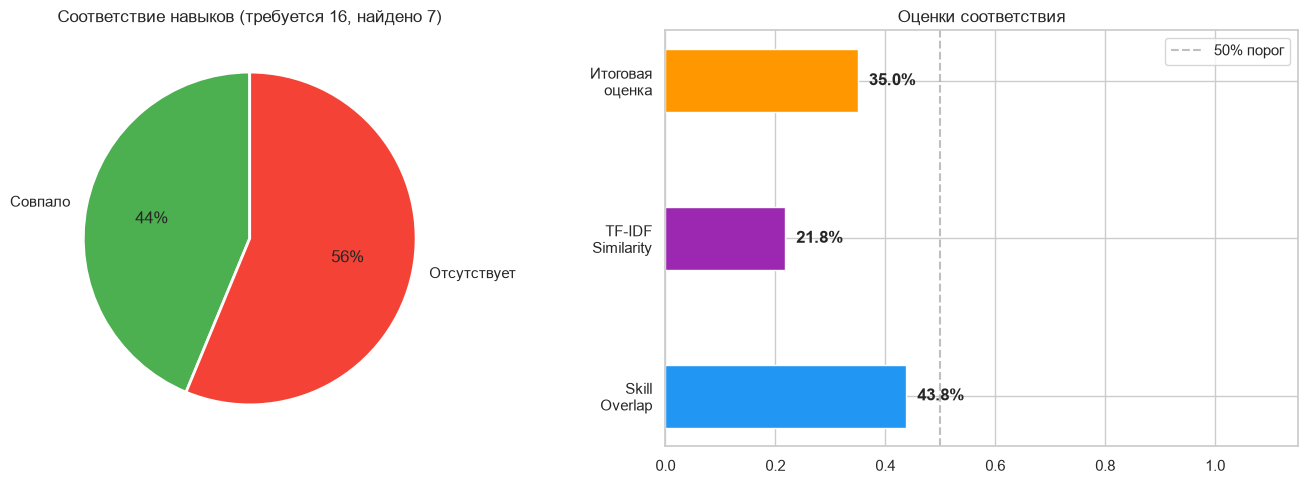

In [41]:
ov = result["skill_overlap"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if len(ov["matched"]) + len(ov["missing"]) > 0:
    axes[0].pie([len(ov["matched"]), len(ov["missing"])], labels=['Совпало', 'Отсутствует'], colors=['#4CAF50', '#F44336'],
                autopct='%1.0f%%', startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
    axes[0].set_title(f"Соответствие навыков (требуется {len(result['job_skills'])}, найдено {len(ov['matched'])})")
vals = [ov['score'], result['tfidf_similarity'], result['final_score']]
bars = axes[1].barh(['Skill\nOverlap', 'TF-IDF\nSimilarity', 'Итоговая\nоценка'], vals, color=['#2196F3', '#9C27B0', '#FF9800'], height=0.4)
axes[1].set_xlim(0, 1.15); axes[1].axvline(0.5, color='gray', linestyle='--', alpha=0.5, label='50% порог')
for b, v in zip(bars, vals):
    axes[1].text(v + 0.02, b.get_y() + b.get_height() / 2, f'{v:.1%}', va='center', fontweight='bold')
axes[1].set_title('Оценки соответствия'); axes[1].legend()
plt.tight_layout(); plt.show()

## 15. Сохранение моделей и проверка
Сохраняются **те же** объекты, для которых посчитаны метрики: словарь из части `vocab` и TF-IDF, обученный на части `train`. Затем модели загружаются с диска и метрики пересчитываются — они должны совпасть. Из `tfidf.pkl` убран служебный атрибут `stop_words_` (список всех отброшенных термов; не нужен для `transform`, но сильно раздувал файл).

In [42]:
import copy
model_dir, tfidf_path, meta_path = OUT_DIR / "nlp_model", OUT_DIR / "tfidf.pkl", OUT_DIR / "model_metadata.json"
if model_dir.exists():
    shutil.rmtree(model_dir)
nlp.to_disk(model_dir)

vec_to_save = copy.deepcopy(matcher.vectorizer)
if hasattr(vec_to_save, "stop_words_"):
    vec_to_save.stop_words_ = None
with open(tfidf_path, "wb") as f:
    pickle.dump(vec_to_save, f)

tf_row, best_row = results[next(n for n in results if "TF-IDF" in n)], results[best_name]
_pick = lambda r: {"vacancies_in_eval": r["rank"]["n_vac"], "rho_within_vacancy": r["rank"]["rho"], "rho_ci95": list(r["rank"]["rho_ci"]),
                   "p10_top20pct": r["rank"]["p10"], "p10_random": r["rank"]["base"],
                   "retrieval_P@1": r["P@1"], "retrieval_P@5": r["P@5"], "retrieval_MRR": r["MRR"]}
metadata = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"), "seed": SEED, "dataset_md5": DATA_MD5,
    "versions": {"python": platform.python_version(), "spacy": spacy.__version__, "spacy_model": nlp_lem.meta.get("version"),
                 "sklearn": __import__("sklearn").__version__, "numpy": np.__version__},
    "split": {"fractions": SPLIT_FRACTIONS, "unit": "vacancy", "group_col": GROUP_COL, "sizes": df["split"].value_counts().to_dict(),
              "vacancies": df.groupby("split")["vacancy_id"].nunique().to_dict(), "duplicates_removed": int(n1 - len(df))},
    "resume_fields": RESUME_FIELDS,
    "ner": {"n_patterns": n_prod, "vocab_split_skills": len(VOCAB_SKILLS), "curated_skills": len(CURATED),
            "test_metrics": {k: res_main[k] for k in ("n_docs", "P_micro", "R_micro", "F1_micro", "P_macro", "R_macro", "F1_macro")},
            "leaky_protocol_F1_micro": variants["1. Утечка: словарь из ВСЕХ строк, оценка на test"][0]["F1_micro"]},
    "tfidf": {"params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in TFIDF_PARAMS.items()},
              "fit_docs": len(train_texts_all), "n_terms": len(vec_to_save.vocabulary_)},
    "matching_test": {"protocol": "vacancy-grouped split; Spearman rho between similarity and matched_score within each vacancy",
                      "n_test": len(te), "n_test_vacancies": int(len(pool)),
                      "tfidf": _pick(tf_row), "product_score": {"vacancies_in_eval": product_rank["n_vac"], "rho_within_vacancy": product_rank["rho"],
                                                              "rho_ci95": list(product_rank["rho_ci"]), "p10_top20pct": product_rank["p10"]},
                      "best_representation": best_name, "best": _pick(best_row)},
}
meta_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
sz = lambda p: sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file()) / 2**20 if Path(p).is_dir() else Path(p).stat().st_size / 2**20
print(f"Сохранено: {model_dir}/ ({sz(model_dir):.1f} MB), {tfidf_path} ({sz(tfidf_path):.2f} MB), {meta_path}")

Сохранено: nlp_model/ (54.9 MB), tfidf.pkl (0.42 MB), model_metadata.json


In [43]:
# проверка «загрузили с диска → метрики совпали»
nlp_back = spacy.load(model_dir)
with open(tfidf_path, "rb") as f:
    vec_back = pickle.load(f)

preds_back = predict_skills(nlp_back, ner_input(test_rows))
res_back = eval_ner(preds_back, gold_test)
assert preds_back == preds_test, "предсказания сохранённой NER-модели отличаются от оценённой"
assert abs(res_back["F1_micro"] - res_main["F1_micro"]) < 1e-12
print(f"✓ NER: сохранённая модель даёт те же предсказания; F1(micro) = {res_back['F1_micro']:.4f}")

_pairs = list(zip(te_texts[:50], te["job_text"].tolist()[:50]))
def _sims(vec):
    return [float(cosine_similarity(vec.transform([clean_text(a)]), vec.transform([clean_text(b)]))[0][0]) for a, b in _pairs]
assert np.allclose(_sims(vec_back), _sims(matcher.vectorizer))
print("✓ TF-IDF: перезагруженный векторизатор даёт те же косинусные сходства")

# согласованность с nlp_pipeline.py (если лежит рядом с сохранёнными моделями)
_pp = OUT_DIR / "nlp_pipeline.py"
if _pp.exists():
    try:
        spec = importlib.util.spec_from_file_location("nlp_pipeline", _pp)
        npl = importlib.util.module_from_spec(spec); spec.loader.exec_module(npl)
        ref = npl.analyze_texts(SAMPLE_RESUME, SAMPLE_JOB)
        print(f"✓ nlp_pipeline.py загрузил артефакты ({npl.MODEL_INFO['ner_model']}); итоговый балл на примере: "
              f"пайплайн {ref['final_score']} vs ноутбук {result['final_score']}")
        assert abs(ref["final_score"] - result["final_score"]) < 1e-3, "nlp_pipeline.py и ноутбук расходятся"
    except Exception as exc:
        print("⚠ проверка nlp_pipeline.py не выполнена:", repr(exc)[:200])
else:
    print(f"(nlp_pipeline.py не найден в {OUT_DIR} — проверка согласованности пропущена)")

✓ NER: сохранённая модель даёт те же предсказания; F1(micro) = 0.9996
✓ TF-IDF: перезагруженный векторизатор даёт те же косинусные сходства
✓ nlp_pipeline.py загрузил артефакты (nlp_model/ (сохранённая модель из ноутбука), +0 навыков вакансий); итоговый балл на примере: пайплайн 0.3499 vs ноутбук 0.3499


## Выводы

In [44]:
m = metadata
print("РЕЗУЛЬТАТЫ ЭТОГО ЗАПУСКА (все числа — на отложенной части test, не участвовавшей в построении словаря и обучении):\n")
print(f"1. NER (словарь из {m['ner']['vocab_split_skills']} навыков vocab-части + {m['ner']['curated_skills']} кураторских = {m['ner']['n_patterns']} паттернов): "
      f"P={m['ner']['test_metrics']['P_micro']:.3f}, R={m['ner']['test_metrics']['R_micro']:.3f}, F1={m['ner']['test_metrics']['F1_micro']:.3f} (micro); "
      f"F1 macro по документам {m['ner']['test_metrics']['F1_macro']:.3f}. С утечкой словаря F1 был бы {m['ner']['leaky_protocol_F1_micro']:.3f}.")
mt = m["matching_test"]
print(f"2. Matching (разбиение по вакансиям; test: {mt['n_test']} резюме, вакансий в оценке {mt['tfidf']['vacancies_in_eval']} из {mt['n_test_vacancies']}): "
      f"TF-IDF ρ внутри вакансии = {mt['tfidf']['rho_within_vacancy']:+.3f} (95% CI [{mt['tfidf']['rho_ci95'][0]:+.3f}; {mt['tfidf']['rho_ci95'][1]:+.3f}]), "
      f"P@10 = {mt['tfidf']['p10_top20pct']:.3f} (случайно ≈ {mt['tfidf']['p10_random']:.3f}); "
      f"итоговый балл продукта: ρ = {mt['product_score']['rho_within_vacancy']:+.3f}; "
      f"лучшее представление — «{best_name}» (ρ = {mt['best']['rho_within_vacancy']:+.3f}).")
print("\nОГРАНИЧЕНИЯ")
print("• Эталон NER — списки навыков, которые кандидаты сами указали в полях skills / related_skils_in_job, а не размеченные спаны в свободном тексте; "
      "поэтому оценивается покрытие словаря неизвестными навыками (OOV), а не качество разбора прозы. Для последнего нужна ручная разметка.")
print("• Эталон matching — matched_score из датасета; его природа неизвестна (пары «резюме — вакансия» могли быть составлены автоматически). "
      "Если ρ внутри вакансии ≈ 0, это значит, что текстовое сходство не воспроизводит эту оценку.")
print("• Классификация «резюме → название вакансии» не используется как метрика: при разбиении по строкам она тривиальна (≈100% — резюме одной вакансии устроены «семейством»), "
      "при разбиении по вакансиям не определена. Подробности и абляция по полям — раздел 10b. Из входа убрано поле responsibilities (RESUME_FIELDS в конфигурации).")
print("• Одно разбиение train/test: доверительные интервалы bootstrap (по вакансиям test) учитывают только выборку теста, но не выбор разбиения; для финального отчёта — повторить с несколькими SEED / кросс-валидацией.")
print("• spaCy-эмбеддинги — статические усреднённые векторы; Sentence-BERT усекает длинные тексты до ~256 токенов.")
print("• Словарь из 40% данных беднее, чем из 100%: для продукта можно после оценки пересобрать словарь на всех данных, но тогда метрики нужно считать на новом отложенном наборе.")

РЕЗУЛЬТАТЫ ЭТОГО ЗАПУСКА (все числа — на отложенной части test, не участвовавшей в построении словаря и обучении):

1. NER (словарь из 3911 навыков vocab-части + 138 кураторских = 3970 паттернов): P=1.000, R=0.999, F1=1.000 (micro); F1 macro по документам 1.000. С утечкой словаря F1 был бы 1.000.
2. Matching (разбиение по вакансиям; test: 2033 резюме, вакансий в оценке 6 из 6): TF-IDF ρ внутри вакансии = +0.299 (95% CI [+0.176; +0.401]), P@10 = 0.650 (случайно ≈ 0.289); итоговый балл продукта: ρ = +0.306; лучшее представление — «spaCy-эмбеддинги (en_core_web_md, mean)» (ρ = +0.330).

ОГРАНИЧЕНИЯ
• Эталон NER — списки навыков, которые кандидаты сами указали в полях skills / related_skils_in_job, а не размеченные спаны в свободном тексте; поэтому оценивается покрытие словаря неизвестными навыками (OOV), а не качество разбора прозы. Для последнего нужна ручная разметка.
• Эталон matching — matched_score из датасета; его природа неизвестна (пары «резюме — вакансия» могли быть составлены ав